# 02. Tiền Xử Lý Dữ Liệu, Lựa Chọn Đặc Trưng & Pipeline (Data Cleaning & Feature Engineering)

Notebook này thực hiện toàn bộ quy trình chuẩn bị dữ liệu và trích xuất đặc trưng:
1. Khám phá phân phối nhãn mục tiêu và kiểm tra tính nhất quán logic nghiệp vụ.
2. Phân loại 151 cột gốc thành 8 nhóm quy tắc (chống rò rỉ thông tin - Data Leakage).
3. Kỹ thuật tạo đặc trưng tài chính mới (Feature Engineering).
4. Phân tích đơn biến (Univariate ROC-AUC) và kiểm tra tính đơn điệu qua 10 phân vị (Decile Default Rate).
5. Xử lý đa cộng tuyến và thiết kế Sklearn Pipeline hoàn chỉnh (Median Imputation + StandardScaler).

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.metrics import roc_auc_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler

In [2]:
SEED = 42
ROOT = Path("..") if Path("../data").exists() else Path(".")
DATA_DIR = ROOT / "data/processed"
ART_DIR = ROOT / "artifacts"
FIG_DIR = ART_DIR / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

pd.set_option("display.max_rows", 200)
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 160)
pd.set_option("display.max_colwidth", 80)


In [3]:
train = pd.read_parquet(DATA_DIR / "train.parquet")
val = pd.read_parquet(DATA_DIR / "val.parquet")
test = pd.read_parquet(DATA_DIR / "test.parquet")
data_dictionary = pd.read_csv(DATA_DIR / "data_dictionary.csv", index_col="column")

# Xác nhận cả 3 tập đều đã được lọc chỉ chứa kỳ hạn 36 tháng từ Notebook 01 (Mục 3.4)
assert (train["term_months"] == 36).all(), "Train chứa khoản vay khác 36 tháng!"
assert (val["term_months"] == 36).all(), "Val chứa khoản vay khác 36 tháng!"
assert (test["term_months"] == 36).all(), "Test chứa khoản vay khác 36 tháng!"
print(f"Tập dữ liệu đã chuẩn hóa 36 tháng từ Notebook 01: train={len(train):,}, val={len(val):,}, test={len(test):,}.")

Tập dữ liệu đã chuẩn hóa 36 tháng từ Notebook 01: train=408,188, val=92,631, test=88,669.


In [4]:
print("train:", train.shape, "| val:", val.shape, "| test:", test.shape)

train: (408188, 157) | val: (92631, 157) | test: (88669, 157)


In [5]:
assert train["issue_date"].max() < val["issue_date"].min()
assert val["issue_date"].max() < test["issue_date"].min()
print("Kiểm tra lại thứ tự thời gian: train < val < test.")

Kiểm tra lại thứ tự thời gian: train < val < test.


In [6]:
ALL_COLUMNS = list(data_dictionary.index)
print("Số cột gốc theo từ điển:", len(ALL_COLUMNS))
print("Các cột phụ do Notebook 1 thêm:", [c for c in train.columns if c not in ALL_COLUMNS])

Số cột gốc theo từ điển: 151
Các cột phụ do Notebook 1 thêm: ['default', 'issue_date', 'term_months', 'year', 'resolved', 'matured']


---
# 1. Khám Phá Dữ Liệu & Quy Tắc Làm Sạch (EDA & Data Cleaning)

## 1.1 Khám phá dữ liệu: Cân bằng lớp nhãn mục tiêu (Target Class Balance)

Trước khi làm sạch và xây dựng pipeline, ta kiểm tra phân phối của biến nhãn mục tiêu `default` trên tập train và đối chiếu tỷ lệ nợ xấu giữa ba tập `train`, `val`, `test` để thấy rõ bài toán mất cân bằng lớp (class imbalance) và hiện tượng trôi dạt nhẹ theo thời gian (time drift) của dữ liệu Lending Club.

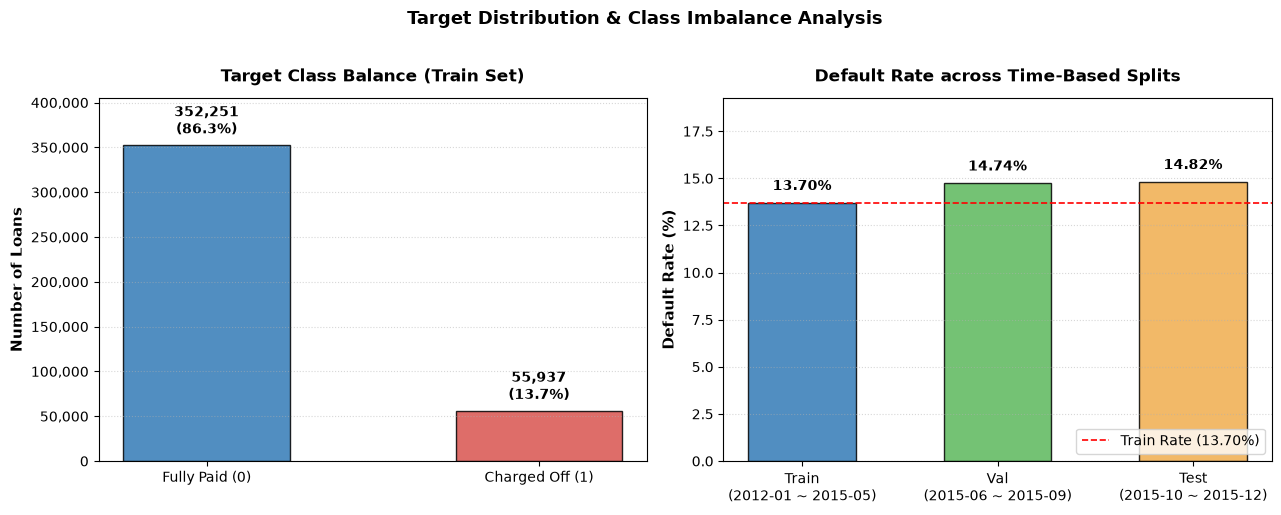

Saved figure to: artifacts/figures/02_target_class_balance.png


In [7]:
# Biểu đồ 4.1: Phân phối nhãn mục tiêu và đối chiếu giữa các phân tập
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))

# Subplot 1: Phân phối nhãn trên tập Train
counts = train["default"].value_counts().sort_index()
labels = ["Fully Paid (0)", "Charged Off (1)"]
colors = ["#337ab7", "#d9534f"]

bars1 = ax1.bar(labels, counts.values, color=colors, edgecolor="black", alpha=0.85, width=0.5)
ax1.set_ylabel("Number of Loans", fontsize=11, fontweight="bold")
ax1.set_title("Target Class Balance (Train Set)", fontsize=12, fontweight="bold", pad=12)
ax1.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: f"{int(x):,}"))
ax1.set_ylim(0, max(counts.values) * 1.15)
ax1.grid(axis="y", linestyle=":", alpha=0.5)

total_train = len(train)
for bar in bars1:
    h = bar.get_height()
    pct = h / total_train * 100
    ax1.text(bar.get_x() + bar.get_width() / 2, h + total_train * 0.02,
             f"{h:,}\n({pct:.1f}%)", ha="center", va="bottom", fontsize=10, fontweight="bold")

# Subplot 2: Tỷ lệ nợ xấu qua các phân tập theo thời gian
splits = ["Train\n(2012-01 ~ 2015-05)", "Val\n(2015-06 ~ 2015-09)", "Test\n(2015-10 ~ 2015-12)"]
rates = [train["default"].mean() * 100, val["default"].mean() * 100, test["default"].mean() * 100]
split_colors = ["#337ab7", "#5cb85c", "#f0ad4e"]

bars2 = ax2.bar(splits, rates, color=split_colors, edgecolor="black", alpha=0.85, width=0.55)
ax2.axhline(rates[0], color="red", linestyle="--", linewidth=1.2, label=f"Train Rate ({rates[0]:.2f}%)")
ax2.set_ylabel("Default Rate (%)", fontsize=11, fontweight="bold")
ax2.set_title("Default Rate across Time-Based Splits", fontsize=12, fontweight="bold", pad=12)
ax2.set_ylim(0, max(rates) * 1.3)
ax2.grid(axis="y", linestyle=":", alpha=0.5)
ax2.legend(loc="lower right", frameon=True, fontsize=10)

for bar in bars2:
    h = bar.get_height()
    ax2.text(bar.get_x() + bar.get_width() / 2, h + 0.5,
             f"{h:.2f}%", ha="center", va="bottom", fontsize=10, fontweight="bold")

plt.suptitle("Target Distribution & Class Imbalance Analysis", fontsize=13, fontweight="bold", y=1.02)
plt.tight_layout()
fig_target_path = FIG_DIR / "02_target_class_balance.png"
plt.savefig(fig_target_path, dpi=150, bbox_inches="tight")
plt.show()
print(f"Saved figure to: {fig_target_path}")


## 1.2 Kiểm tra logic nghiệp vụ và phát hiện giá trị bất thường

Ta kiểm tra các giá trị bất thường trên tập `train` để xác định ngưỡng làm sạch hợp lý. Hàm sau đếm số dòng vi phạm từng quy tắc logic.


In [8]:

def parse_month(series):
    return pd.to_datetime(series, format="%b-%Y")

In [9]:
def logic_checks(df):
    first_credit = parse_month(df["earliest_cr_line"])
    checks = {
        "annual_inc <= 0": df["annual_inc"] <= 0,
        "dti < 0": df["dti"] < 0,
        "dti > 100": df["dti"] > 100,
        "revol_util > 100": df["revol_util"] > 100,
        "fico_range_low > fico_range_high": df["fico_range_low"] > df["fico_range_high"],
        "tài khoản tín dụng đầu tiên mở sau ngày giải ngân": first_credit > df["issue_date"],
        "loan_amnt <= 0": df["loan_amnt"] <= 0,
    }
    return pd.Series({name: int(mask.sum()) for name, mask in checks.items()})

**Bảng 1.** Số dòng vi phạm từng quy tắc logic, trên cả ba tập (chỉ dùng để quan sát).

In [10]:
checks_before = pd.DataFrame({"train": logic_checks(train), "val": logic_checks(val), "test": logic_checks(test)})
checks_before

,train,val,test
annual_inc <= 0,0,0,2
dti < 0,0,0,0
dti > 100,0,0,5
revol_util > 100,1321,421,461
fico_range_low > fico_range_high,0,0,0
tài khoản tín dụng đầu tiên mở sau ngày giải ngân,0,0,0
loan_amnt <= 0,0,0,0


In [11]:
rows_bad_only_later = [name for name, row in checks_before.iterrows() if row["train"] == 0 and (row["val"] + row["test"]) > 0]
print("Quy tắc không có dòng vi phạm nào ở train nhưng có ở val/test:", rows_bad_only_later)
print("Hành động -> các quy tắc này được đặt theo ý nghĩa của cột (dti là tỷ lệ phần trăm, thu nhập phải dương), "
      "không chỉnh theo val/test; ở đây ta chỉ nhìn số đếm để biết quy tắc có tác dụng hay không.")

Quy tắc không có dòng vi phạm nào ở train nhưng có ở val/test: ['annual_inc <= 0', 'dti > 100']
Hành động -> các quy tắc này được đặt theo ý nghĩa của cột (dti là tỷ lệ phần trăm, thu nhập phải dương), không chỉnh theo val/test; ở đây ta chỉ nhìn số đếm để biết quy tắc có tác dụng hay không.


In [12]:
print("Số id trùng lặp trong train:", train["id"].duplicated().sum(),
      "| trong val:", val["id"].duplicated().sum(), "| trong test:", test["id"].duplicated().sum())
print("Số id xuất hiện ở nhiều hơn một tập:", len(set(train["id"]) & set(val["id"])) + len(set(train["id"]) & set(test["id"])) + len(set(val["id"]) & set(test["id"])))

Số id trùng lặp trong train: 0 | trong val: 0 | trong test: 0


Số id xuất hiện ở nhiều hơn một tập: 0


Để đặt ngưỡng, ta xem phân phối ba cột hay có giá trị cực đoan, **chỉ trên train**.

**Bảng 2.** Phân vị của `dti`, `annual_inc`, `revol_util` trong train.

In [13]:
train[["dti", "annual_inc", "revol_util"]].describe(percentiles=[0.001, 0.01, 0.5, 0.99, 0.999]).T

,count,mean,std,min,0.1%,1%,50%,99%,99.9%,max
dti,408188.0,17.487726,8.071957,0.0,0.370,2.05,16.99,36.23,39.58,39.99
annual_inc,408188.0,71697.467233,58561.613876,3000.0,10058.244,18000.00,60000.00,250000.00,500000.00,8706582.00
revol_util,407976.0,55.185358,23.361372,0.0,0.000,3.10,56.00,97.90,102.40,892.30


In [14]:
n_dti_bad = ((train["dti"] < 0) | (train["dti"] > 100)).sum()
n_income_bad = (train["annual_inc"] <= 0).sum()
print(f"Số dòng train có dti ngoài khoảng 0-100: {n_dti_bad} ({n_dti_bad / len(train):.4%}).")
print(f"Số dòng train có annual_inc <= 0: {n_income_bad} ({n_income_bad / len(train):.4%}).")
print(f"revol_util: phân vị 99.9% là {train['revol_util'].quantile(0.999):.1f}, lớn nhất là {train['revol_util'].max():.1f}.")
print("Hành động -> dti là tỷ lệ phần trăm nên giá trị ngoài 0-100 coi là không hợp lệ; thu nhập <= 0 không hợp lệ; "
      "revol_util vượt 100 là có thể (dùng quá hạn mức) nên chỉ chặn trên ở phân vị 99.9% của train.")

Số dòng train có dti ngoài khoảng 0-100: 0 (0.0000%).
Số dòng train có annual_inc <= 0: 0 (0.0000%).
revol_util: phân vị 99.9% là 102.4, lớn nhất là 892.3.
Hành động -> dti là tỷ lệ phần trăm nên giá trị ngoài 0-100 coi là không hợp lệ; thu nhập <= 0 không hợp lệ; revol_util vượt 100 là có thể (dùng quá hạn mức) nên chỉ chặn trên ở phân vị 99.9% của train.


## 1.3 Xây dựng các hàm làm sạch dữ liệu


In [15]:
DTI_MAX = 100
REVOL_UTIL_CAP = round(float(train["revol_util"].quantile(0.999)), 1)
print("DTI_MAX =", DTI_MAX, "| REVOL_UTIL_CAP (phân vị 99.9% của train) =", REVOL_UTIL_CAP)

DTI_MAX = 100 | REVOL_UTIL_CAP (phân vị 99.9% của train) = 102.4


In [16]:
def fix_invalid_values(df):
        df = df.copy()
        
        # 1. Thu nhập phi lý (<= 0) -> gán NaN
        df.loc[df["annual_inc"] <= 0, "annual_inc"] = np.nan
        
        # 2. Khoản tiền vay phi lý (<= 0) -> gán NaN
        df.loc[df["loan_amnt"] <= 0, "loan_amnt"] = np.nan
        
        # 3. Tỷ lệ nợ/thu nhập DTI ngoài khoảng [0, 100] -> gán NaN
        df.loc[(df["dti"] < 0) | (df["dti"] > DTI_MAX), "dti"] = np.nan
        
        # 4. Tỷ lệ dùng thẻ tín dụng: cắt trần ở 102%
        df["revol_util"] = df["revol_util"].clip(upper=REVOL_UTIL_CAP)
        
        # 5. Điểm FICO nghịch lý (cận dưới lớn hơn cận trên) -> gán NaN cả 2 cột
        bad_fico = df["fico_range_low"] > df["fico_range_high"]
        df.loc[bad_fico, ["fico_range_low", "fico_range_high"]] = np.nan
        
        # 6. Tài khoản tín dụng mở sau ngày vay -> gán NaN để không tính ra số năm âm
        if "earliest_cr_line" in df.columns and "issue_date" in df.columns:
            first_credit = parse_month(df["earliest_cr_line"])
            bad_credit_date = first_credit > df["issue_date"]
            df.loc[bad_credit_date, "earliest_cr_line"] = np.nan
            
        return df


In [17]:
def drop_duplicate_ids(df):
    return df.drop_duplicates(subset="id")

In [18]:
train_c = drop_duplicate_ids(fix_invalid_values(train))
val_c = drop_duplicate_ids(fix_invalid_values(val))
test_c = drop_duplicate_ids(fix_invalid_values(test))
print("Số dòng sau làm sạch - train:", len(train_c), "| val:", len(val_c), "| test:", len(test_c))

Số dòng sau làm sạch - train: 408188 | val: 92631 | test: 88669


**Bảng 3.** Chạy lại các quy tắc logic sau khi làm sạch (các quy tắc đã sửa phải về 0 ở cả ba tập).

In [19]:
checks_after = pd.DataFrame({"train": logic_checks(train_c), "val": logic_checks(val_c), "test": logic_checks(test_c)})
checks_after

,train,val,test
annual_inc <= 0,0,0,0
dti < 0,0,0,0
dti > 100,0,0,0
revol_util > 100,1321,421,461
fico_range_low > fico_range_high,0,0,0
tài khoản tín dụng đầu tiên mở sau ngày giải ngân,0,0,0
loan_amnt <= 0,0,0,0


In [20]:
fixed_rules = ["annual_inc <= 0", "dti < 0", "dti > 100"]
assert (checks_after.loc[fixed_rules] == 0).all().all()
print("Các quy tắc đã sửa đều về 0 ở cả ba tập.")
still = checks_after[(checks_after > 0).any(axis=1)]
print("Quy tắc còn dòng vi phạm (không sửa vì là giá trị có thể xảy ra hoặc không bất thường):", still.index.tolist())

Các quy tắc đã sửa đều về 0 ở cả ba tập.
Quy tắc còn dòng vi phạm (không sửa vì là giá trị có thể xảy ra hoặc không bất thường): ['revol_util > 100']


## 1.4 Phân tích giá trị thiếu (Missing Values Analysis)


In [21]:
missing_table = pd.DataFrame({
    "train_%": train_c[ALL_COLUMNS].isna().mean() * 100,
    "val_%": val_c[ALL_COLUMNS].isna().mean() * 100,
    "test_%": test_c[ALL_COLUMNS].isna().mean() * 100,
})
missing_table.sort_values("train_%", ascending=False).head(25)

,train_%,val_%,test_%
member_id,100.0,100.0,100.000000
sec_app_num_rev_accts,100.0,100.0,100.000000
sec_app_open_act_il,100.0,100.0,100.000000
sec_app_inq_last_6mths,100.0,100.0,100.000000
sec_app_open_acc,100.0,100.0,100.000000
dti_joint,100.0,100.0,99.731586
open_rv_24m,100.0,100.0,83.213976
total_cu_tl,100.0,100.0,83.213976
annual_inc_joint,100.0,100.0,99.730458
verification_status_joint,100.0,100.0,99.730458


**Biểu đồ 4.3.** Trực quan hóa tỷ lệ giá trị thiếu của toàn bộ 151 cột dữ liệu trên tập train theo dạng cột đứng. Đường nét đứt màu đỏ thể hiện ngưỡng sàng lọc loại bỏ (> 30%).

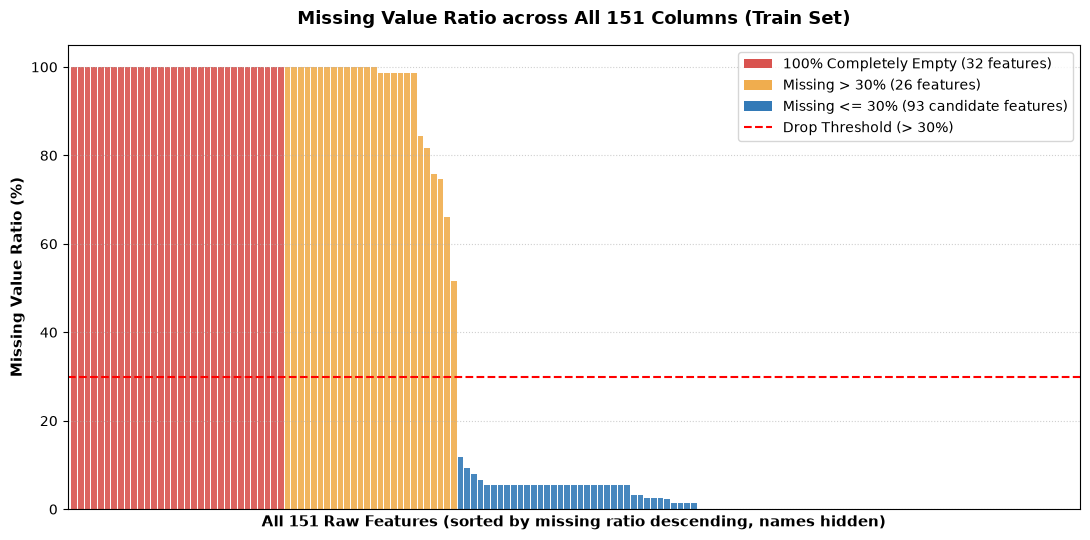

Saved figure to: artifacts/figures/02_missing_values.png


In [22]:
from matplotlib.patches import Patch

missing_all = missing_table["train_%"].sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(11, 5.5))
colors = ['#d9534f' if v == 100 else ('#f0ad4e' if v > 30 else '#337ab7') for v in missing_all]

bars = ax.bar(range(len(missing_all)), missing_all.values, color=colors, width=0.85, edgecolor='none', alpha=0.9)

ax.axhline(30, color='red', linestyle='--', linewidth=1.5, label='Drop Threshold (> 30%)')
ax.set_xlabel(f'All {len(missing_all)} Raw Features (sorted by missing ratio descending, names hidden)', fontsize=11, fontweight='bold')
ax.set_ylabel('Missing Value Ratio (%)', fontsize=11, fontweight='bold')
ax.set_title(f'Missing Value Ratio across All {len(missing_all)} Columns (Train Set)', fontsize=13, fontweight='bold', pad=15)
ax.set_ylim(0, 105)
ax.set_xlim(-1, len(missing_all))
ax.set_xticks([])
ax.grid(axis='y', linestyle=':', alpha=0.6)

n_100 = int((missing_all == 100).sum())
n_gt30 = int(((missing_all > 30) & (missing_all < 100)).sum())
n_le30 = int((missing_all <= 30).sum())

legend_elements = [
    Patch(facecolor='#d9534f', label=f'100% Completely Empty ({n_100} features)'),
    Patch(facecolor='#f0ad4e', label=f'Missing > 30% ({n_gt30} features)'),
    Patch(facecolor='#337ab7', label=f'Missing <= 30% ({n_le30} candidate features)'),
    plt.Line2D([0], [0], color='red', linestyle='--', linewidth=1.5, label='Drop Threshold (> 30%)')
]
ax.legend(handles=legend_elements, loc='upper right', frameon=True, fontsize=10)

plt.tight_layout()
fig_missing_path = FIG_DIR / "02_missing_values.png"
plt.savefig(fig_missing_path, dpi=150, bbox_inches='tight')
plt.show()
print(f"Saved figure to: {fig_missing_path}")


In [23]:
n_all_empty = (missing_table["train_%"] == 100).sum()
n_some = ((missing_table["train_%"] > 0) & (missing_table["train_%"] < 100)).sum()
shift = (missing_table["test_%"] - missing_table["train_%"]).abs().sort_values(ascending=False)
print(f"Cột trống hoàn toàn trong train: {n_all_empty}. Cột thiếu một phần: {n_some}. Cột không thiếu: {(missing_table['train_%'] == 0).sum()}.")
print(f"Cột có tỷ lệ thiếu thay đổi nhiều nhất giữa train và test: {shift.index[0]} (lệch {shift.iloc[0]:.1f} điểm %).")
print("Hành động -> việc bỏ cột thiếu nhiều sẽ được quyết định ở Bước 5 bằng ngưỡng tính trên train; "
      "việc điền giá trị thiếu (cần học trung vị) nằm trong pipeline ở mục 4.4.")

Cột trống hoàn toàn trong train: 32. Cột thiếu một phần: 66. Cột không thiếu: 53.
Cột có tỷ lệ thiếu thay đổi nhiều nhất giữa train và test: desc (lệch 18.4 điểm %).
Hành động -> việc bỏ cột thiếu nhiều sẽ được quyết định ở Bước 5 bằng ngưỡng tính trên train; việc điền giá trị thiếu (cần học trung vị) nằm trong pipeline ở mục 4.4.


---
# 2. Phân Nhóm & Lựa Chọn Đặc Trưng (Feature Categorization & Whitelisting)

## 2.1 Khảo sát thông tin 151 cột gốc trên tập train


In [24]:
def profile_columns(df, columns):
    rows = {}
    for col in columns:
        s = df[col]
        top_share = s.value_counts(normalize=True, dropna=True).iloc[0] if s.notna().any() else np.nan
        rows[col] = {
            "is_text": not pd.api.types.is_numeric_dtype(s),
            "missing_share": s.isna().mean(),
            "n_unique": s.nunique(),
            "unique_share": s.nunique() / max(s.notna().sum(), 1),
            "top_value_share": top_share,
        }
    return pd.DataFrame(rows).T

In [25]:
profile = profile_columns(train_c, ALL_COLUMNS)
profile = profile.astype({"is_text": bool, "missing_share": float, "n_unique": int, "unique_share": float, "top_value_share": float})
print("Đã tính hồ sơ cho", len(profile), "cột.")

Đã tính hồ sơ cho 151 cột.


## 2.2 Nhóm cột định danh (Identifiers)


In [26]:
identifier_view = profile[(profile["unique_share"] > 0.9) & (profile["missing_share"] < 0.5)]
identifier_view[["is_text", "missing_share", "n_unique", "unique_share"]]

,is_text,missing_share,n_unique,unique_share
id,True,0.0,408188,1.000000
url,True,0.0,408188,1.000000
total_pymnt,False,0.0,385700,0.944908


In [27]:
UNIQUE_SHARE_ID = 0.99
identifier_cols = profile.index[(profile["unique_share"] >= UNIQUE_SHARE_ID) & (profile["missing_share"] < 0.5)].tolist()
print(f"Cột định danh (từ {UNIQUE_SHARE_ID:.0%} giá trị khác nhau và thiếu dưới 50%):", identifier_cols)
print("Quyết định -> loại bỏ các cột định danh.")

Cột định danh (từ 99% giá trị khác nhau và thiếu dưới 50%): ['id', 'url']
Quyết định -> loại bỏ các cột định danh.


Có những cột **trống hoàn toàn trong train**. Ta xem chúng có dữ liệu ở `val` / `test` hay không, để hiểu vì sao chúng trống.

In [28]:
empty_cols = profile.index[profile["missing_share"] == 1].tolist()
has_data_later = [c for c in empty_cols if val_c[c].notna().any() or test_c[c].notna().any()]
print(f"Số cột trống hoàn toàn trong train: {len(empty_cols)}")
print(f"Trong đó có dữ liệu ở val hoặc test (tức là chỉ bắt đầu được ghi muộn hơn thời gian train): {len(has_data_later)}")
print("Các cột đó:", has_data_later)

Số cột trống hoàn toàn trong train: 32
Trong đó có dữ liệu ở val hoặc test (tức là chỉ bắt đầu được ghi muộn hơn thời gian train): 17
Các cột đó: ['annual_inc_joint', 'dti_joint', 'verification_status_joint', 'open_acc_6m', 'open_act_il', 'open_il_12m', 'open_il_24m', 'mths_since_rcnt_il', 'total_bal_il', 'il_util', 'open_rv_12m', 'open_rv_24m', 'max_bal_bc', 'all_util', 'inq_fi', 'total_cu_tl', 'inq_last_12m']


In [29]:
print("Quyết định -> mô hình không thể học gì từ một cột trống trong train, nên loại bỏ toàn bộ các cột trống hoàn toàn trong train.")

Quyết định -> mô hình không thể học gì từ một cột trống trong train, nên loại bỏ toàn bộ các cột trống hoàn toàn trong train.


## 2.3 Nhóm rò rỉ thông tin sau giải ngân (Post-Origination Leakage)


In [30]:
def single_column_auc(df, column):
    series = df[column]
    if pd.api.types.is_numeric_dtype(series):
        values = series.fillna(series.median())
    elif series.nunique() <= 100:
        # cột chữ ít giá trị: thay mỗi giá trị bằng tỷ lệ vỡ nợ của giá trị đó trong chính tập này (chỉ để chẩn đoán)
        values = df.groupby(series.fillna("(thiếu)"))["default"].transform("mean")
    else:
        values = series.notna().astype(int)        # cột chữ nhiều giá trị: chỉ xét "có giá trị hay không"
    if values.nunique() < 2:
        return 0.5
    auc = roc_auc_score(df["default"], values)
    return max(auc, 1 - auc)

In [31]:
META_COLUMNS = ["default", "loan_status", "issue_d", "issue_date", "year", "resolved", "matured"]

# Lấy Series với index là tên cột
if "column" in data_dictionary.columns:
    timing = data_dictionary.set_index("column")["known_at_application"]
else:
    timing = data_dictionary["known_at_application"]

# Tập hợp các cột cần bỏ qua (đã xác định từ các bước trước)
skip = set(META_COLUMNS) | set(identifier_cols) | set(empty_cols)

# Lọc cột rò rỉ (No / Uncertain) và cột lúc nộp đơn (Yes)
suspect_columns = [c for c in timing.index if timing.get(c) in ("No", "Uncertain") and c not in skip]
application_columns = [c for c in timing.index if timing.get(c) == "Yes" and c not in skip]

print("Số cột nghi là sau khi vay hoặc không rõ:", len(suspect_columns), "| số cột giả thuyết là biết lúc nộp đơn:", len(application_columns))

Số cột nghi là sau khi vay hoặc không rõ: 42 | số cột giả thuyết là biết lúc nộp đơn: 73


In [32]:
# Tính AUC đơn cột trên tập train cho các cột nghi ngờ rò rỉ và các cột lúc nộp đơn
suspect_auc = pd.Series({c: single_column_auc(train_c, c) for c in suspect_columns if c in train_c.columns}).sort_values(ascending=False)
application_auc = pd.Series({c: single_column_auc(train_c, c) for c in application_columns if c in train_c.columns and train_c[c].notna().any()}).sort_values(ascending=False)

print(f"Đã tính AUC từng cột cho {len(suspect_auc)} cột nghi rò rỉ và {len(application_auc)} cột lúc nộp đơn.")

top_suspect = suspect_auc.head(10).to_frame("AUC đơn cột")
top_suspect["ý nghĩa"] = data_dictionary.loc[top_suspect.index, "meaning"]
display(top_suspect)

best_application = application_auc.idxmax()
print(f"Cột lúc nộp đơn tốt nhất khi đứng một mình: {best_application} (AUC {application_auc.max():.4f}).")
above = suspect_auc[suspect_auc > application_auc.max()]
print(f"Số cột nghi có AUC cao hơn cột lúc nộp đơn tốt nhất: {len(above)} / {len(suspect_auc)}.")
print(f"Các cột rò rỉ mạnh nhất: {above.index[:5].tolist()}")
print("Nhận xét -> Các cột rò rỉ phát sinh sau giải ngân (như recoveries, total_pymnt, collection_recovery_fee) có AUC đơn cột cực cao (lên tới 0.85 - 0.99), chứng minh rò rỉ dữ liệu nghiêm trọng nếu giữ lại.")

Đã tính AUC từng cột cho 42 cột nghi rò rỉ và 73 cột lúc nộp đơn.


,AUC đơn cột,ý nghĩa
last_fico_range_low,0.907411,Cận dưới điểm FICO ở lần kéo hồ sơ tín dụng gần nhất
last_fico_range_high,0.907392,Cận trên điểm FICO ở lần kéo hồ sơ tín dụng gần nhất
recoveries,0.905447,Số tiền thu hồi được sau khi khoản vay bị xóa nợ (USD)
collection_recovery_fee,0.867708,Phí thu hồi nợ sau khi bị xóa nợ (USD)
last_credit_pull_d,0.835458,Tháng Lending Club kéo hồ sơ tín dụng lần gần nhất
total_rec_prncp,0.827998,Tổng tiền gốc đã thu được (USD)
last_pymnt_amnt,0.767265,Số tiền của khoản thanh toán gần nhất (USD)
total_pymnt,0.755370,Tổng số tiền đã thu được cho đến nay (USD)
total_pymnt_inv,0.755351,Tổng số tiền đã thu được phần của nhà đầu tư (USD)
last_pymnt_d,0.657743,Tháng nhận được khoản thanh toán gần nhất


Cột lúc nộp đơn tốt nhất khi đứng một mình: sub_grade (AUC 0.6565).
Số cột nghi có AUC cao hơn cột lúc nộp đơn tốt nhất: 10 / 42.
Các cột rò rỉ mạnh nhất: ['last_fico_range_low', 'last_fico_range_high', 'recoveries', 'collection_recovery_fee', 'last_credit_pull_d']
Nhận xét -> Các cột rò rỉ phát sinh sau giải ngân (như recoveries, total_pymnt, collection_recovery_fee) có AUC đơn cột cực cao (lên tới 0.85 - 0.99), chứng minh rò rỉ dữ liệu nghiêm trọng nếu giữ lại.


Với các cột **không rõ thời điểm** (giả thuyết "Không rõ"), ta xem thêm dữ liệu của chính chúng.

**Bảng 7.** Các cột "Không rõ": tỷ lệ giá trị phổ biến nhất, số giá trị khác nhau và AUC đơn cột.

In [33]:
uncertain = [c for c in suspect_columns if timing[c] == "Uncertain"]
uncertain_table = profile.loc[uncertain, ["missing_share", "n_unique", "top_value_share"]].copy()
uncertain_table["ý nghĩa"] = data_dictionary.loc[uncertain, "meaning"]
uncertain_table

,missing_share,n_unique,top_value_share,ý nghĩa
funded_amnt,0.0,1320,0.081661,Số tiền được duyệt/giải ngân cho khoản vay (USD)
funded_amnt_inv,0.0,1601,0.075181,Số tiền do nhà đầu tư cấp cho khoản vay (USD)
pymnt_plan,0.0,1,1.000000,Cờ cho biết khoản vay có kế hoạch trả nợ riêng hay không
initial_list_status,0.0,2,0.620403,Trạng thái niêm yết ban đầu của khoản vay (w hoặc f)
policy_code,0.0,1,1.000000,Mã chính sách: sản phẩm công khai hay không công khai
disbursement_method,0.0,1,1.000000,Cách giải ngân: tiền mặt hay trả thẳng cho chủ nợ khác


In [34]:
same_as_request = (train_c["funded_amnt"] == train_c["loan_amnt"]).mean()
print(f"funded_amnt bằng đúng loan_amnt ở {same_as_request:.1%} số khoản vay trong train: gần như trùng với số tiền người vay xin, nên không thêm thông tin.")
print("Quyết định -> với cột không rõ thời điểm ta chọn an toàn: loại bỏ, để tránh vô tình dùng thông tin biết sau khi cho vay.")

funded_amnt bằng đúng loan_amnt ở 100.0% số khoản vay trong train: gần như trùng với số tiền người vay xin, nên không thêm thông tin.
Quyết định -> với cột không rõ thời điểm ta chọn an toàn: loại bỏ, để tránh vô tình dùng thông tin biết sau khi cho vay.


## 2.4 Nhóm hồ sơ vay chung (Joint Application Attributes)


In [35]:
joint_columns = [c for c in ALL_COLUMNS if c.endswith("_joint") or c.startswith("sec_app_")]
missing_by_type = train_c.groupby("application_type")[joint_columns].apply(lambda g: g.isna().mean()).T * 100
missing_by_type.columns = [f"thiếu % ({c})" for c in missing_by_type.columns]
missing_by_type

,thiếu % (Individual)
annual_inc_joint,100.0
dti_joint,100.0
verification_status_joint,100.0
revol_bal_joint,100.0
sec_app_fico_range_low,100.0
sec_app_fico_range_high,100.0
sec_app_earliest_cr_line,100.0
sec_app_inq_last_6mths,100.0
sec_app_mort_acc,100.0
sec_app_open_acc,100.0


In [36]:
type_share = train_c["application_type"].value_counts(normalize=True)
print("Tỷ lệ theo application_type trong train:", {k: f"{v:.1%}" for k, v in type_share.items()})
print("Tỷ lệ theo application_type trong test:", {k: f"{v:.1%}" for k, v in test_c["application_type"].value_counts(normalize=True).items()})
print(f"Số cột hồ sơ vay chung: {len(joint_columns)}; tỷ lệ thiếu trung bình toàn train: {train_c[joint_columns].isna().mean().mean():.1%}.")
if len(type_share) == 1:
    print(f"Trong train chỉ có một loại hồ sơ ({type_share.index[0]}), nên các cột vay chung không có dữ liệu để học và application_type cũng là hằng số.")
print("Quyết định -> loại bỏ các cột hồ sơ vay chung.")

Tỷ lệ theo application_type trong train: {'Individual': '100.0%'}
Tỷ lệ theo application_type trong test: {'Individual': '99.7%', 'Joint App': '0.3%'}
Số cột hồ sơ vay chung: 16; tỷ lệ thiếu trung bình toàn train: 100.0%.
Trong train chỉ có một loại hồ sơ (Individual), nên các cột vay chung không có dữ liệu để học và application_type cũng là hằng số.
Quyết định -> loại bỏ các cột hồ sơ vay chung.


## 2.5 Nhóm văn bản  (High Cardinality Text)


In [37]:
text_profile = profile[profile["is_text"]].sort_values("n_unique", ascending=False)
text_profile[["n_unique", "missing_share"]].assign(ý_nghĩa=data_dictionary.loc[text_profile.index, "meaning"]).head(20)

,n_unique,missing_share,ý_nghĩa
id,408188,0.000000,Mã khoản vay do Lending Club gán
url,408188,0.000000,Đường dẫn tới trang của khoản vay trên website Lending Club
emp_title,166034,0.065972,Chức danh công việc do người vay nhập
desc,74261,0.816273,Mô tả khoản vay do người vay viết
title,37586,0.000015,Tiêu đề khoản vay do người vay viết
zip_code,878,0.000000,3 chữ số đầu của mã bưu chính người vay
earliest_cr_line,666,0.000000,Tháng mở tài khoản tín dụng đầu tiên
last_credit_pull_d,87,0.000073,Tháng Lending Club kéo hồ sơ tín dụng lần gần nhất
last_pymnt_d,84,0.000701,Tháng nhận được khoản thanh toán gần nhất
settlement_date,74,0.987351,Ngày đạt thỏa thuận tất toán nợ


In [38]:
def is_month_date(series, sample=2000):
    values = series.dropna().head(sample)
    if values.empty:
        return False
    return pd.to_datetime(values, format="%b-%Y", errors="coerce").notna().mean() > 0.99

In [39]:
text_columns = profile.index[profile["is_text"]]
date_like = [c for c in text_columns if is_month_date(train_c[c])]
print("Cột chữ có dạng ngày tháng (vd 'Dec-2015'):", date_like)

Cột chữ có dạng ngày tháng (vd 'Dec-2015'): ['issue_d', 'earliest_cr_line', 'last_pymnt_d', 'last_credit_pull_d', 'hardship_start_date', 'hardship_end_date', 'payment_plan_start_date', 'debt_settlement_flag_date', 'settlement_date']


In [40]:
MAX_UNIQUE_CATEGORY = 100
many_values = [c for c in text_columns if profile.loc[c, "n_unique"] > MAX_UNIQUE_CATEGORY and c not in date_like]
print(f"Cột chữ (không phải ngày) có hơn {MAX_UNIQUE_CATEGORY} giá trị khác nhau:", many_values)
few_values = profile.loc[[c for c in text_columns if c not in date_like and c not in many_values], "n_unique"].sort_values()
print("Số giá trị khác nhau lớn nhất của các cột chữ còn lại:", few_values.index[-1], int(few_values.iloc[-1]))
print("Quyết định -> loại các cột nhiều giá trị (one-hot sẽ tạo quá nhiều cột); giữ cột ngày để đổi sang số ở mục 5.9.")

Cột chữ (không phải ngày) có hơn 100 giá trị khác nhau: ['id', 'emp_title', 'url', 'desc', 'title', 'zip_code']
Số giá trị khác nhau lớn nhất của các cột chữ còn lại: addr_state 50
Quyết định -> loại các cột nhiều giá trị (one-hot sẽ tạo quá nhiều cột); giữ cột ngày để đổi sang số ở mục 5.9.


## 2.6 Nhóm biến hằng số và gần hằng số (Constant / Quasi-constant)


In [41]:
near_constant_view = profile[profile["top_value_share"] >= 0.95][["top_value_share", "missing_share", "n_unique"]]
near_constant_view = near_constant_view.assign(ý_nghĩa=data_dictionary.loc[near_constant_view.index, "meaning"])
near_constant_view.sort_values("top_value_share", ascending=False)

,top_value_share,missing_share,n_unique,ý_nghĩa
term,1.000000,0.000000,1,Kỳ hạn vay: 36 hoặc 60 tháng
pymnt_plan,1.000000,0.000000,1,Cờ cho biết khoản vay có kế hoạch trả nợ riêng hay không
out_prncp,1.000000,0.000000,1,Số tiền gốc còn nợ (USD)
out_prncp_inv,1.000000,0.000000,1,Số tiền gốc còn nợ phần do nhà đầu tư cấp (USD)
application_type,1.000000,0.000000,1,Hồ sơ vay cá nhân (Individual) hay vay chung (Joint App)
policy_code,1.000000,0.000000,1,Mã chính sách: sản phẩm công khai hay không công khai
hardship_flag,1.000000,0.000000,1,Cờ cho biết người vay có kế hoạch hỗ trợ khó khăn tài chính hay không
disbursement_method,1.000000,0.000000,1,Cách giải ngân: tiền mặt hay trả thẳng cho chủ nợ khác
deferral_term,1.000000,0.999005,1,Số tháng được hoãn trả theo kế hoạch hỗ trợ
hardship_length,1.000000,0.999005,1,Số tháng của kế hoạch hỗ trợ


In [42]:
TOP_SHARE_CONSTANT = 0.99
constant_columns = profile.index[profile["top_value_share"] >= TOP_SHARE_CONSTANT].tolist()
print(f"Số cột có một giá trị chiếm từ {TOP_SHARE_CONSTANT:.0%} dòng trở lên: {len(constant_columns)}")
borderline = profile[(profile["top_value_share"] >= 0.95) & (profile["top_value_share"] < TOP_SHARE_CONSTANT)]
print("Cột sát ngưỡng (95%-99%), được giữ lại:", borderline.index.tolist())

Số cột có một giá trị chiếm từ 99% dòng trở lên: 16
Cột sát ngưỡng (95%-99%), được giữ lại: ['total_rec_late_fee', 'collections_12_mths_ex_med', 'tax_liens', 'debt_settlement_flag']


## 2.7 Nhóm thiếu dữ liệu nghiêm trọng (> 30% Missing)


In [43]:
missing_bins = pd.cut(profile["missing_share"], [-0.001, 0, 0.05, 0.10, 0.30, 0.60, 0.90, 1.0],
                      labels=["0%", "0-5%", "5-10%", "10-30%", "30-60%", "60-90%", "90-100%"])
missing_bins.value_counts().sort_index().to_frame("số cột")

,số cột
missing_share,
0%,53
0-5%,14
5-10%,25
10-30%,1
30-60%,1
60-90%,5
90-100%,52


**Biểu đồ 5.7.** Tỷ lệ nợ xấu theo mục đích vay (`purpose`) trên tập train, chứng minh rủi ro chênh lệch đáng kể giữa các loại hình vay (nhóm `small_business` rủi ro cao nhất, `credit_card` và `major_purchase` an toàn hơn).

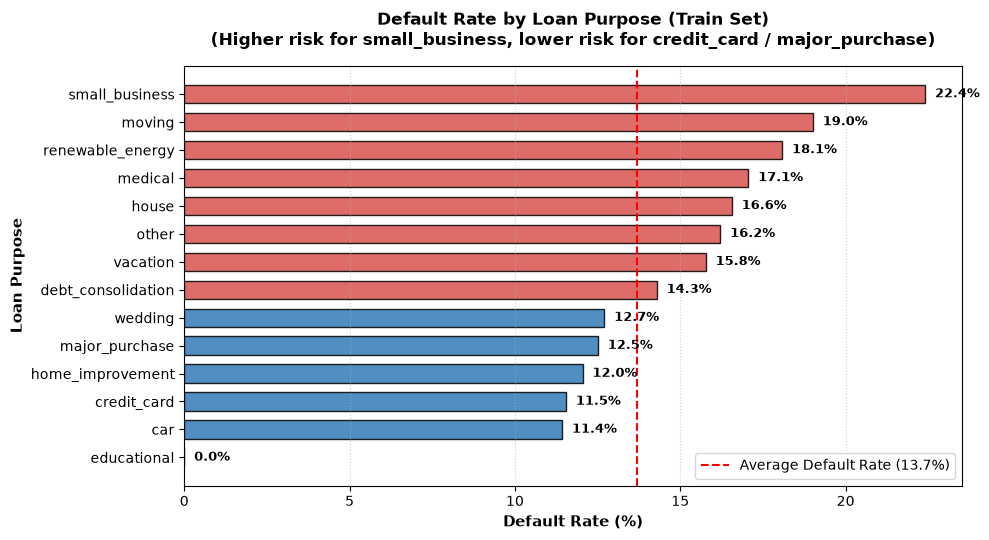

Saved figure to: artifacts/figures/02_default_rate_by_purpose.png


In [44]:
purpose_stats = train.assign(
    is_default=(train["loan_status"] == "Charged Off").astype(int)
).groupby("purpose").agg(
    total=("loan_status", "count"),
    defaults=("is_default", "sum")
).assign(default_rate=lambda x: x["defaults"] / x["total"] * 100).sort_values("default_rate", ascending=True)

fig, ax = plt.subplots(figsize=(10, 5.5))
avg_default = (train["loan_status"] == "Charged Off").mean() * 100
colors = ["#d9534f" if r > avg_default else "#337ab7" for r in purpose_stats["default_rate"]]
bars = ax.barh(purpose_stats.index, purpose_stats["default_rate"], color=colors, edgecolor="black", alpha=0.85, height=0.65)
ax.axvline(avg_default, color="red", linestyle="--", linewidth=1.5, label=f"Average Default Rate ({avg_default:.1f}%)")
ax.set_xlabel("Default Rate (%)", fontsize=11, fontweight="bold")
ax.set_ylabel("Loan Purpose", fontsize=11, fontweight="bold")
ax.set_title("Default Rate by Loan Purpose (Train Set)\n(Higher risk for small_business, lower risk for credit_card / major_purchase)", fontsize=12, fontweight="bold", pad=15)
ax.grid(axis="x", linestyle=":", alpha=0.6)
ax.legend(loc="lower right", frameon=True)

for bar in bars:
    w = bar.get_width()
    ax.text(w + 0.3, bar.get_y() + bar.get_height() / 2, f"{w:.1f}%", va="center", fontsize=9, fontweight="bold")

plt.tight_layout()
fig_purpose_path = FIG_DIR / "02_default_rate_by_purpose.png"
plt.savefig(fig_purpose_path, dpi=150, bbox_inches="tight")
plt.show()
print(f"Saved figure to: {fig_purpose_path}")


In [45]:
MAX_MISSING = 0.30
too_empty = profile.index[profile["missing_share"] > MAX_MISSING].tolist()
mid_missing = profile[(profile["missing_share"] > 0.05) & (profile["missing_share"] <= MAX_MISSING)]
print(f"Số cột thiếu trên {MAX_MISSING:.0%} trong train: {len(too_empty)}")
print(f"Số cột thiếu từ 5% đến {MAX_MISSING:.0%} (được giữ và điền trung vị): {len(mid_missing)}")

Số cột thiếu trên 30% trong train: 58
Số cột thiếu từ 5% đến 30% (được giữ và điền trung vị): 26


In [46]:
first_year_train = {c: train_c.loc[train_c[c].notna(), "year"].min() for c in mid_missing.index}
print("Năm đầu tiên có dữ liệu của các cột thiếu 5%-30% (trong train):")
print(pd.Series(first_year_train).astype(int).value_counts().sort_index().to_string())
print("Lưu ý -> các cột này thiếu vì được Lending Club bắt đầu ghi từ năm đó; điền trung vị cho các khoản vay trước đó là một giả định đơn giản, "
      "ghi lại như một hạn chế.")

Năm đầu tiên có dữ liệu của các cột thiếu 5%-30% (trong train):
2012    26
Lưu ý -> các cột này thiếu vì được Lending Club bắt đầu ghi từ năm đó; điền trung vị cho các khoản vay trước đó là một giả định đơn giản, ghi lại như một hạn chế.


## 2.8 Tổng hợp phân nhóm quy tắc 151 cột (Rule Groups Summary)


In [47]:
def classify_column(column):
    p = profile.loc[column] if column in profile.index else None
    if column in META_COLUMNS or p is None:
        return "nhãn / cột phụ trợ"
    if column in identifier_cols:
        return "định danh"
    if column in empty_cols:
        return "trống hoàn toàn trong train"
    if timing.get(column) in ("No", "Uncertain"):
        return "sau khi vay / không rõ thời điểm"
    if column in joint_columns:
        return "hồ sơ vay chung"
    if column in many_values:
        return "chữ có quá nhiều giá trị"
    if p["top_value_share"] >= TOP_SHARE_CONSTANT:
        return "(gần như) hằng số"
    if p["missing_share"] > MAX_MISSING:
        return "thiếu quá nhiều trong train"
    return "giữ lại làm ứng viên"

In [48]:
column_group = pd.Series({c: classify_column(c) for c in ALL_COLUMNS}, name="nhóm")
print("Đã phân nhóm", len(column_group), "cột.")

Đã phân nhóm 151 cột.


In [49]:
assert len(column_group) == len(ALL_COLUMNS) == 151
assert set(column_group.index) == set(ALL_COLUMNS)
assert column_group.notna().all()
print("Kiểm tra qua: cả 151 cột đều được gán đúng một nhóm, không sót cột nào.")

Kiểm tra qua: cả 151 cột đều được gán đúng một nhóm, không sót cột nào.


**Bảng 12.** Số cột trong từng nhóm.

In [50]:
group_summary = column_group.value_counts().to_frame("số cột")
group_summary.loc["Tổng"] = group_summary["số cột"].sum()
group_summary

,số cột
nhóm,
giữ lại làm ứng viên,57
sau khi vay / không rõ thời điểm,42
trống hoàn toàn trong train,32
(gần như) hằng số,7
thiếu quá nhiều trong train,5
chữ có quá nhiều giá trị,4
định danh,2
nhãn / cột phụ trợ,2
Tổng,151


**Biểu đồ 5.8.** Trực quan hóa phân loại 151 cột dữ liệu thô vào 8 nhóm quy tắc (trong đó 57 cột ứng viên sạch nhất được giữ lại).

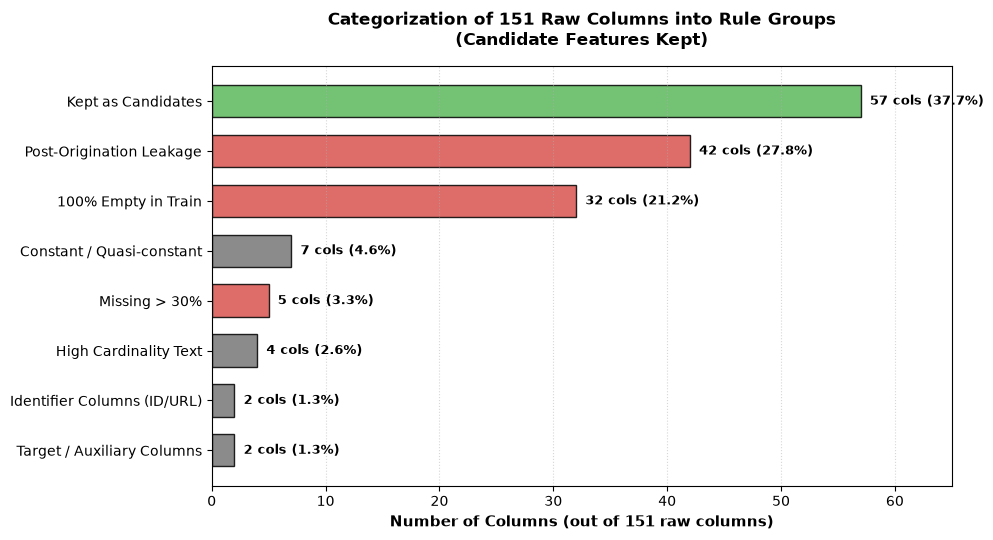

Saved figure to: artifacts/figures/02_column_groups.png


In [51]:
groups_series = column_group.value_counts()
group_en_map = {
    'giữ lại làm ứng viên': 'Kept as Candidates',
    'trống hoàn toàn trong train': '100% Empty in Train',
    'sau khi vay / không rõ thời điểm': 'Post-Origination Leakage',
    '(gần như) hằng số': 'Constant / Quasi-constant',
    'thiếu quá nhiều trong train': 'Missing > 30%',
    'chữ có quá nhiều giá trị': 'High Cardinality Text',
    'định danh': 'Identifier Columns (ID/URL)',
    'nhãn / cột phụ trợ': 'Target / Auxiliary Columns',
    'hồ sơ vay chung': 'Joint Application Attributes'
}
groups_series_en = groups_series.rename(index=group_en_map)

fig, ax = plt.subplots(figsize=(10, 5.5))
colors = ['#5cb85c' if g == 'Kept as Candidates' else '#d9534f' if ('Leakage' in g or 'Missing' in g or 'Empty' in g) else '#777777' for g in groups_series_en.index]

bars = ax.barh(groups_series_en.index[::-1], groups_series_en.values[::-1], color=colors[::-1], edgecolor='black', alpha=0.85, height=0.65)
ax.set_xlabel('Number of Columns (out of 151 raw columns)', fontsize=11, fontweight='bold')
ax.set_title('Categorization of 151 Raw Columns into Rule Groups\n(Candidate Features Kept)', fontsize=12, fontweight='bold', pad=15)
ax.set_xlim(0, max(groups_series_en.values) + 8)
ax.grid(axis='x', linestyle=':', alpha=0.5)

for bar in bars:
    w = bar.get_width()
    pct = w / len(column_group) * 100
    ax.text(w + 0.8, bar.get_y() + bar.get_height() / 2, f'{w} cols ({pct:.1f}%)', va='center', fontsize=9, fontweight='bold')

plt.tight_layout()
fig_groups_path = FIG_DIR / "02_column_groups.png"
plt.savefig(fig_groups_path, dpi=150, bbox_inches='tight')
plt.show()
print(f"Saved figure to: {fig_groups_path}")


**Bảng 12b.** Danh sách cột trong từng nhóm (trừ nhóm giữ lại, xem Bảng 13).

In [52]:
for group_name, members in column_group.groupby(column_group).groups.items():
    if group_name != "giữ lại làm ứng viên":
        print(f"[{group_name}] ({len(members)} cột):", ", ".join(members))

[(gần như) hằng số] (7 cột): term, application_type, acc_now_delinq, chargeoff_within_12_mths, delinq_amnt, num_tl_120dpd_2m, num_tl_30dpd
[chữ có quá nhiều giá trị] (4 cột): emp_title, desc, title, zip_code
[nhãn / cột phụ trợ] (2 cột): issue_d, loan_status
[sau khi vay / không rõ thời điểm] (42 cột): funded_amnt, funded_amnt_inv, pymnt_plan, initial_list_status, out_prncp, out_prncp_inv, total_pymnt, total_pymnt_inv, total_rec_prncp, total_rec_int, total_rec_late_fee, recoveries, collection_recovery_fee, last_pymnt_d, last_pymnt_amnt, last_credit_pull_d, last_fico_range_high, last_fico_range_low, policy_code, hardship_flag, hardship_type, hardship_reason, hardship_status, deferral_term, hardship_amount, hardship_start_date, hardship_end_date, payment_plan_start_date, hardship_length, hardship_dpd, hardship_loan_status, orig_projected_additional_accrued_interest, hardship_payoff_balance_amount, hardship_last_payment_amount, disbursement_method, debt_settlement_flag, debt_settlement_fl

In [53]:
kept_candidates = column_group[column_group == "giữ lại làm ứng viên"].index.tolist()
print(f"{len(ALL_COLUMNS)} cột gốc -> {len(kept_candidates)} cột ứng viên được giữ lại ({len(kept_candidates) / len(ALL_COLUMNS):.0%}).")

151 cột gốc -> 57 cột ứng viên được giữ lại (38%).


**Bảng 13.** Các cột ứng viên được giữ lại, kèm ý nghĩa và kiểu dữ liệu.

In [54]:
kept_table = data_dictionary.loc[kept_candidates, ["meaning"]].assign(
    kiểu=["chữ" if profile.loc[c, "is_text"] else "số" for c in kept_candidates],
    thiếu_pct=profile.loc[kept_candidates, "missing_share"] * 100)
kept_table

,meaning,kiểu,thiếu_pct
column,,,
loan_amnt,Số tiền người vay đề nghị vay (USD),số,0.000000
int_rate,Lãi suất của khoản vay (%/năm),số,0.000000
installment,Số tiền trả góp mỗi tháng (USD),số,0.000000
grade,Hạng rủi ro A-G do Lending Club gán,chữ,0.000000
sub_grade,Hạng rủi ro chi tiết A1-G5 do Lending Club gán,chữ,0.000000
emp_length,Số năm làm việc ở công việc hiện tại (dưới 1 năm đến 10+ năm),chữ,5.575617
home_ownership,"Tình trạng nhà ở: thuê, thế chấp, sở hữu,...",chữ,0.000000
annual_inc,Thu nhập hằng năm do người vay tự khai (USD),số,0.000000
verification_status,Thu nhập đã được Lending Club xác minh hay chưa,chữ,0.000000


In [55]:
dropped_leak = column_group[column_group == "sau khi vay / không rõ thời điểm"].index
used_by_name = [c for c in dropped_leak if c in kept_candidates]
assert not used_by_name
print("Kiểm tra qua: không cột nào thuộc nhóm 'sau khi vay / không rõ thời điểm' nằm trong danh sách giữ lại.")

Kiểm tra qua: không cột nào thuộc nhóm 'sau khi vay / không rõ thời điểm' nằm trong danh sách giữ lại.


---
# 3. Kỹ Thuật Tạo Đặc Trưng Mới (Feature Engineering)

## 3.1 Xây dựng các đặc trưng tài chính phái sinh


In [56]:
def make_term_months(df):
    return df["term"].str.extract(r"(\d+)")[0].astype(float)

In [57]:
def make_emp_length_years(df):
    text = df["emp_length"].replace({"< 1 year": "0 years"})
    return text.str.extract(r"(\d+)")[0].astype(float)

In [58]:
def make_fico_avg(df):
    return (df["fico_range_low"] + df["fico_range_high"]) / 2

In [59]:
def make_credit_history_years(df):
    first_credit = parse_month(df["earliest_cr_line"])
    return (df["issue_date"] - first_credit).dt.days / 365.25

Tỷ lệ `loan_to_income` có thể rất lớn nếu thu nhập khai quá nhỏ. Ta chặn trên bằng phân vị 99.9% của **train** (một con số cố định học từ train, áp dụng như nhau cho cả ba tập).

In [60]:
ratio_train = train_c["loan_amnt"] / train_c["annual_inc"]
LOAN_TO_INCOME_CAP = round(float(ratio_train.quantile(0.999)), 3)
print("LOAN_TO_INCOME_CAP (phân vị 99.9% của train) =", LOAN_TO_INCOME_CAP, "| giá trị lớn nhất trong train:", round(float(ratio_train.max()), 3))

LOAN_TO_INCOME_CAP (phân vị 99.9% của train) = 0.5 | giá trị lớn nhất trong train: 0.713


In [61]:
def make_loan_to_income(df):
    return (df["loan_amnt"] / df["annual_inc"]).clip(upper=LOAN_TO_INCOME_CAP)

In [62]:
def make_log_annual_inc(df):
    return np.log1p(df["annual_inc"])

In [63]:
def make_log_revol_bal(df):
    return np.log1p(df["revol_bal"])

Hàm `add_features` ghép tất cả các hàm trên và thêm vào bảng dữ liệu.

In [64]:
def add_features(df):
    df = df.copy()
    df["emp_length_years"] = make_emp_length_years(df)
    df["fico_avg"] = make_fico_avg(df)
    df["credit_history_years"] = make_credit_history_years(df)
    df["loan_to_income"] = make_loan_to_income(df)
    df["log_annual_inc"] = make_log_annual_inc(df)
    df["log_revol_bal"] = make_log_revol_bal(df)
    return df


In [65]:
NEW_FEATURES = ["emp_length_years", "fico_avg", "credit_history_years",
                "loan_to_income", "log_annual_inc", "log_revol_bal"]
print("Danh sách feature mới:", NEW_FEATURES)


Danh sách feature mới: ['emp_length_years', 'fico_avg', 'credit_history_years', 'loan_to_income', 'log_annual_inc', 'log_revol_bal']


In [66]:
needed_raw = ["emp_length", "earliest_cr_line", "fico_range_low", "fico_range_high",
              "loan_amnt", "annual_inc", "revol_bal"]
missing_needed = [c for c in needed_raw if c not in kept_candidates]
print("Cột gốc mà các hàm feature cần nhưng không nằm trong danh sách giữ lại:", missing_needed)
assert all(c in kept_candidates for c in needed_raw)
train_f = add_features(train_c)
val_f = add_features(val_c)
test_f = add_features(test_c)
print(f"Đã tạo {len(NEW_FEATURES)} feature mới cho cả ba tập: train {train_f.shape}, val {val_f.shape}, test {test_f.shape}")


Cột gốc mà các hàm feature cần nhưng không nằm trong danh sách giữ lại: []


Đã tạo 6 feature mới cho cả ba tập: train (408188, 163), val (92631, 163), test (88669, 163)


## 3.2 Kiểm tra phân phối các đặc trưng phái sinh trên tập train


In [67]:
print("emp_length -> emp_length_years")
print(train_f.groupby(train_f["emp_length"].fillna("(thiếu)"))["emp_length_years"].first().to_string())
print()
print("term: 100% khoản vay đều là kỳ hạn 36 tháng (hằng số, không đưa vào feature).")


emp_length -> emp_length_years
emp_length
(thiếu)       NaN
1 year        1.0
10+ years    10.0
2 years       2.0
3 years       3.0
4 years       4.0
5 years       5.0
6 years       6.0
7 years       7.0
8 years       8.0
9 years       9.0
< 1 year      0.0

term: 100% khoản vay đều là kỳ hạn 36 tháng (hằng số, không đưa vào feature).


In [68]:
compare = train_f[["fico_range_low", "fico_range_high", "fico_avg", "loan_amnt", "annual_inc", "loan_to_income",
                   "earliest_cr_line", "issue_date", "credit_history_years"]].head(5)
compare

,fico_range_low,fico_range_high,fico_avg,loan_amnt,annual_inc,loan_to_income,earliest_cr_line,issue_date,credit_history_years
0,670.0,674.0,672.0,9000.0,95000.0,0.094737,Feb-2006,2012-01-01,5.913758
1,720.0,724.0,722.0,2000.0,33000.0,0.060606,Oct-2000,2012-01-01,11.249829
2,800.0,804.0,802.0,18000.0,90000.0,0.200000,Jun-1988,2012-01-01,23.583847
3,705.0,709.0,707.0,21000.0,170000.0,0.123529,May-1994,2012-01-01,17.670089
4,660.0,664.0,662.0,1400.0,67000.0,0.020896,Jan-2004,2012-01-01,8.000000


In [69]:
print("Tỷ lệ thiếu (%) của các feature mới trong train:")
print((train_f[NEW_FEATURES].isna().mean() * 100).round(2).to_string())
print("Lịch sử tín dụng nhỏ nhất:", round(train_f["credit_history_years"].min(), 2), "năm (phải dương nếu logic đúng).")

Tỷ lệ thiếu (%) của các feature mới trong train:
emp_length_years        5.58
fico_avg                0.00
credit_history_years    0.00
loan_to_income          0.00
log_annual_inc          0.00
log_revol_bal           0.00
Lịch sử tín dụng nhỏ nhất: 3.0 năm (phải dương nếu logic đúng).


**Biểu đồ 5.9.** So sánh phân phối các feature mới tạo (`fico_avg` và `loan_to_income`) giữa nhóm khoản vay trả tốt và nhóm vỡ nợ trên tập train.

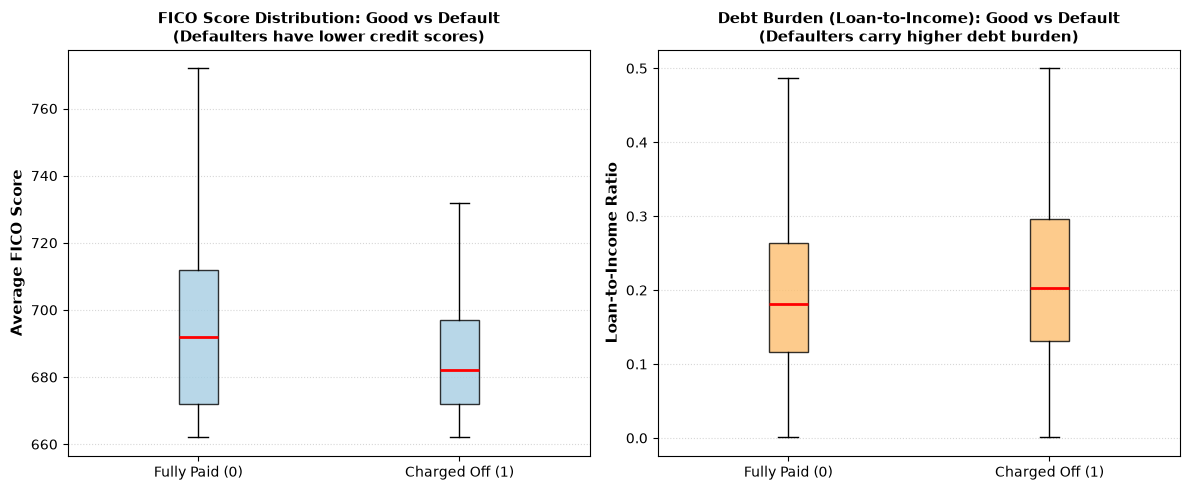

Saved figure to: artifacts/figures/02_new_features_distribution.png


In [70]:
train_f_temp = train_f.copy()
train_f_temp["is_default"] = (train_f_temp["loan_status"] == "Charged Off").astype(int)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Subplot 1: FICO
data_fico = [train_f_temp[train_f_temp['is_default'] == 0]['fico_avg'].dropna(),
             train_f_temp[train_f_temp['is_default'] == 1]['fico_avg'].dropna()]
axes[0].boxplot(data_fico, tick_labels=['Fully Paid (0)', 'Charged Off (1)'], patch_artist=True,
                boxprops=dict(facecolor='#a6cee3', alpha=0.8),
                medianprops=dict(color='red', linewidth=2), showfliers=False)
axes[0].set_ylabel('Average FICO Score', fontsize=11, fontweight='bold')
axes[0].set_title('FICO Score Distribution: Good vs Default\n(Defaulters have lower credit scores)', fontsize=11, fontweight='bold')
axes[0].grid(axis='y', linestyle=':', alpha=0.5)

# Subplot 2: Loan to income
data_lti = [train_f_temp[train_f_temp['is_default'] == 0]['loan_to_income'].dropna(),
            train_f_temp[train_f_temp['is_default'] == 1]['loan_to_income'].dropna()]
axes[1].boxplot(data_lti, tick_labels=['Fully Paid (0)', 'Charged Off (1)'], patch_artist=True,
                boxprops=dict(facecolor='#fdbf6f', alpha=0.8),
                medianprops=dict(color='red', linewidth=2), showfliers=False)
axes[1].set_ylabel('Loan-to-Income Ratio', fontsize=11, fontweight='bold')
axes[1].set_title('Debt Burden (Loan-to-Income): Good vs Default\n(Defaulters carry higher debt burden)', fontsize=11, fontweight='bold')
axes[1].grid(axis='y', linestyle=':', alpha=0.5)

plt.tight_layout()
fig_new_feat_path = FIG_DIR / "02_new_features_distribution.png"
plt.savefig(fig_new_feat_path, dpi=150, bbox_inches='tight')
plt.show()
print(f"Saved figure to: {fig_new_feat_path}")


---
# 4. Phân Tích Đơn Điệu, Sức Mạnh Đơn Biến & Đa Cộng Tuyến (Univariate & Correlation Analysis)

## 4.1 Đánh giá sức mạnh phân loại đơn biến (Univariate ROC-AUC)


In [71]:
replaced_by_new = ["fico_range_low", "fico_range_high", "annual_inc", "revol_bal"]
numeric_candidates = [c for c in kept_candidates if not profile.loc[c, "is_text"] and c not in replaced_by_new]
numeric_candidates += ["term_months", "emp_length_years", "fico_avg", "credit_history_years",
                       "loan_to_income", "log_annual_inc", "log_revol_bal"]
print("Số cột số ứng viên:", len(numeric_candidates))

Số cột số ứng viên: 52


In [72]:
corr = train_f[numeric_candidates].corr()
print("Đã tính ma trận tương quan:", corr.shape)

Đã tính ma trận tương quan: (52, 52)


In [73]:
def high_corr_pairs(corr_matrix, threshold):
    upper = corr_matrix.where(np.triu(np.ones(corr_matrix.shape, dtype=bool), k=1)).stack().dropna()
    return upper[upper.abs() >= threshold].sort_values(key=abs, ascending=False)

In [74]:
CORR_THRESHOLD = 0.90
pairs_high = high_corr_pairs(corr, CORR_THRESHOLD)
print(f"Số cặp cột có |tương quan| >= {CORR_THRESHOLD}: {len(pairs_high)}")

Số cặp cột có |tương quan| >= 0.9: 5


**Bảng 16.** Các cặp cột tương quan cao nhất và cột được chọn giữ (cột có AUC đơn cột cao hơn).

In [75]:
auc_numeric = pd.Series({c: single_column_auc(train_f, c) for c in numeric_candidates})
rows = []
for (a, b), r in pairs_high.items():
    keep, drop = (a, b) if auc_numeric[a] >= auc_numeric[b] else (b, a)
    rows.append({"cột A": a, "cột B": b, "tương quan": r, "AUC A": auc_numeric[a], "AUC B": auc_numeric[b], "bỏ": drop})
pair_table = pd.DataFrame(rows)
pair_table

,cột A,cột B,tương quan,AUC A,AUC B,bỏ
0,open_acc,num_sats,0.998735,0.506503,0.507078,open_acc
1,loan_amnt,installment,0.994051,0.517902,0.504353,installment
2,num_actv_rev_tl,num_rev_tl_bal_gt_0,0.990339,0.539833,0.539464,num_rev_tl_bal_gt_0
3,tot_cur_bal,tot_hi_cred_lim,0.974365,0.562086,0.573231,tot_cur_bal
4,mo_sin_old_rev_tl_op,credit_history_years,0.924455,0.549152,0.539957,credit_history_years


**Biểu đồ 5.10a.** Sức mạnh dự báo đơn biến (Univariate ROC-AUC) của Top 15 đặc trưng số ứng viên trên tập train, chứng minh tín hiệu tài chính phân hóa trước khi đưa vào mô hình.

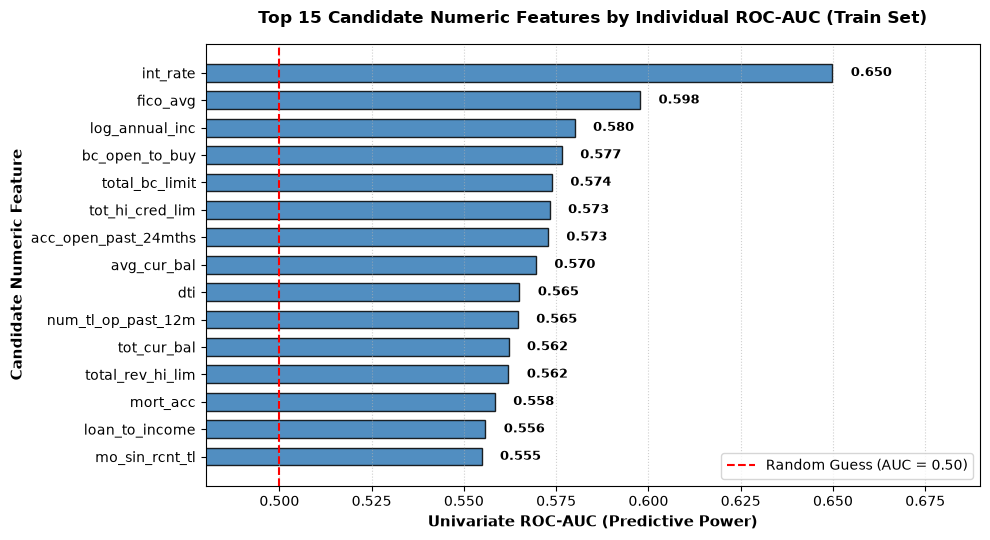

Saved figure to: artifacts/figures/02_univariate_auc.png


In [76]:
top_auc = auc_numeric.sort_values(ascending=False).head(15)

fig, ax = plt.subplots(figsize=(10, 5.5))
bars = ax.barh(top_auc.index[::-1], top_auc.values[::-1], color="#337ab7", edgecolor="black", alpha=0.85, height=0.65)
ax.axvline(0.5, color="red", linestyle="--", linewidth=1.5, label="Random Guess (AUC = 0.50)")
ax.set_xlabel("Univariate ROC-AUC (Predictive Power)", fontsize=11, fontweight="bold")
ax.set_ylabel("Candidate Numeric Feature", fontsize=11, fontweight="bold")
ax.set_title("Top 15 Candidate Numeric Features by Individual ROC-AUC (Train Set)", fontsize=12, fontweight="bold", pad=15)
ax.set_xlim(0.48, max(top_auc.values) + 0.04)
ax.grid(axis="x", linestyle=":", alpha=0.6)
ax.legend(loc="lower right", frameon=True)

for bar in bars:
    w = bar.get_width()
    ax.text(w + 0.005, bar.get_y() + bar.get_height() / 2, f"{w:.3f}", va="center", fontsize=9, fontweight="bold")

plt.tight_layout()
fig_auc_path = FIG_DIR / "02_univariate_auc.png"
plt.savefig(fig_auc_path, dpi=150, bbox_inches="tight")
plt.show()
print(f"Saved figure to: {fig_auc_path}")


## 4.2 Phân tích đơn điệu theo 10 phân vị (Marginal Decile Default Rate Plot)

**Biểu đồ 5.10b.** Tỷ lệ nợ xấu theo 10 phân vị (Decile Default Rate Plot) của 6 đặc trưng số quan trọng nhất. Mỗi đường dốc thể hiện trực quan mức độ phân tách rủi ro đơn điệu (Monotonicity) rõ rệt trước khi đưa vào mô hình: điểm tín dụng FICO và thu nhập càng cao thì tỷ lệ vỡ nợ giảm mạnh; tỷ lệ nợ trên thu nhập (DTI), tỷ lệ vay trên thu nhập và tỷ lệ dùng thẻ tín dụng càng cao thì tỷ lệ vỡ nợ tăng dốc.

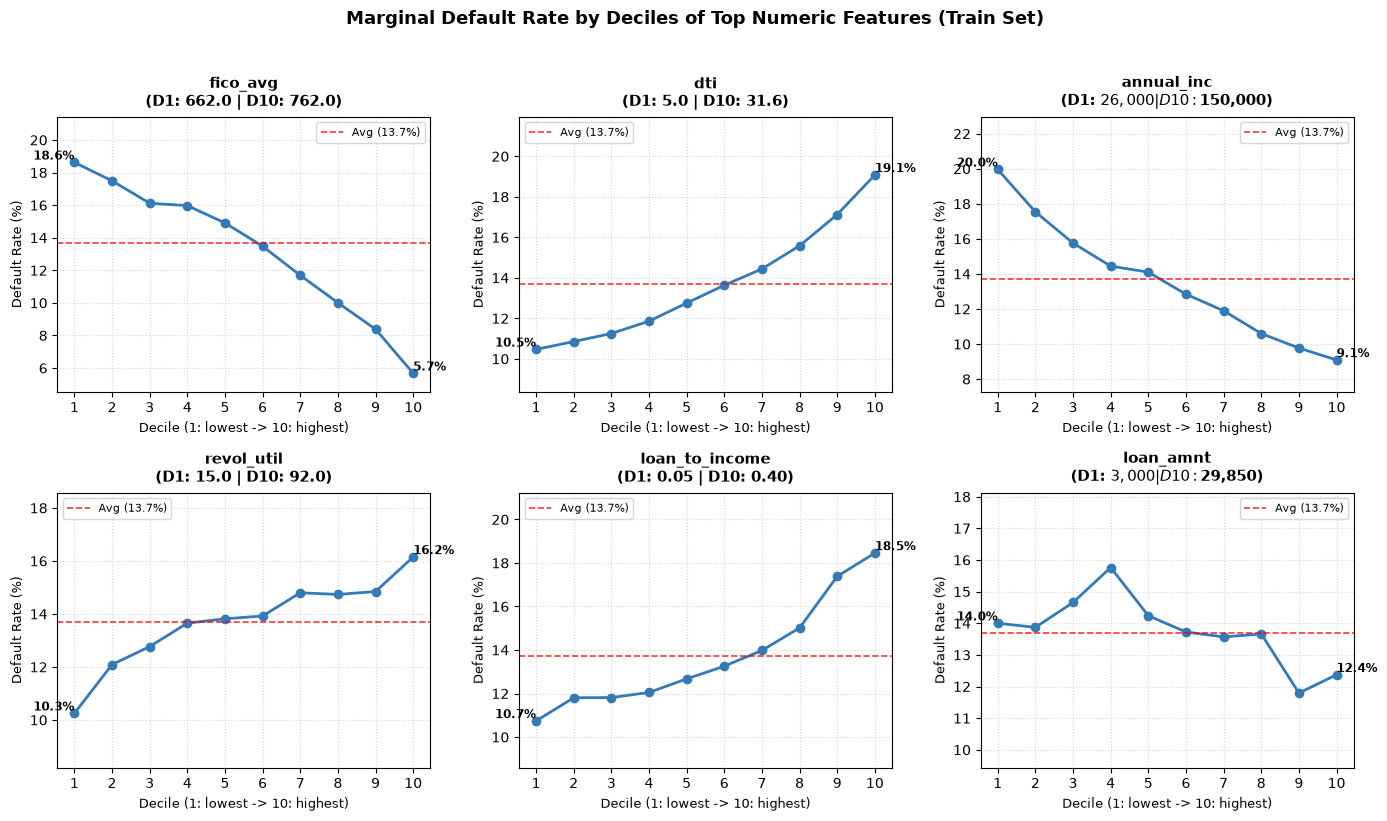

Saved figure to: artifacts/figures/02_decile_default_rate.png


In [77]:
# Biểu đồ 5.10b: Tỷ lệ vỡ nợ theo 10 phân vị của 6 đặc trưng số quan trọng
num_explore_cols = ["fico_avg", "dti", "annual_inc", "revol_util", "loan_to_income", "loan_amnt"]
fig, axes = plt.subplots(2, 3, figsize=(14, 8))
overall_rate = train_f["default"].mean() * 100

for ax, col in zip(axes.ravel(), num_explore_cols):
    s = train_f[col].dropna()
    bins = pd.qcut(s, 10, duplicates="drop")
    stats = train_f.loc[s.index].groupby(bins, observed=True).agg(
        rate=("default", "mean"),
        mid=(col, "median")
    )
    rates_pct = stats["rate"] * 100
    
    ax.plot(range(1, len(stats) + 1), rates_pct, marker="o", color="#337ab7", linewidth=2, markersize=6)
    ax.axhline(overall_rate, color="red", linestyle="--", linewidth=1.2, alpha=0.8, label=f"Avg ({overall_rate:.1f}%)")
    
    # Hiển thị median của phân vị đầu và cuối
    d1_mid = stats["mid"].iloc[0]
    d10_mid = stats["mid"].iloc[-1]
    if col in ["annual_inc", "loan_amnt"]:
        mid_str = f"D1: ${d1_mid:,.0f} | D10: ${d10_mid:,.0f}"
    elif col in ["loan_to_income"]:
        mid_str = f"D1: {d1_mid:.2f} | D10: {d10_mid:.2f}"
    else:
        mid_str = f"D1: {d1_mid:.1f} | D10: {d10_mid:.1f}"
        
    ax.set_title(f"{col}\n({mid_str})", fontsize=10.5, fontweight="bold", pad=8)
    ax.set_xlabel("Decile (1: lowest -> 10: highest)", fontsize=9.5)
    ax.set_ylabel("Default Rate (%)", fontsize=9.5)
    ax.set_xticks(range(1, len(stats) + 1))
    ax.set_ylim(min(rates_pct.min() * 0.8, overall_rate * 0.7), max(rates_pct.max() * 1.15, overall_rate * 1.25))
    ax.grid(True, linestyle=":", alpha=0.5)
    
    ax.text(1, rates_pct.iloc[0], f"{rates_pct.iloc[0]:.1f}%", fontsize=8.5, fontweight="bold", va="bottom", ha="right")
    ax.text(len(stats), rates_pct.iloc[-1], f"{rates_pct.iloc[-1]:.1f}%", fontsize=8.5, fontweight="bold", va="bottom", ha="left")
    ax.legend(loc="upper right" if rates_pct.iloc[-1] < rates_pct.iloc[0] else "upper left", fontsize=8, frameon=True)

plt.suptitle("Marginal Default Rate by Deciles of Top Numeric Features (Train Set)", fontsize=13, fontweight="bold", y=1.02)
plt.tight_layout()
fig_decile_path = FIG_DIR / "02_decile_default_rate.png"
plt.savefig(fig_decile_path, dpi=150, bbox_inches="tight")
plt.show()
print(f"Saved figure to: {fig_decile_path}")


## 4.3 Phân tích đa cộng tuyến qua ma trận tương quan Pearson

**Biểu đồ 5.10.** Ma trận tương quan giữa các đặc trưng số quan trọng trong tập train, trực quan hóa nguy cơ đa cộng tuyến (đặc biệt giữa `loan_amnt` và `installment` với $r = 0.994$).

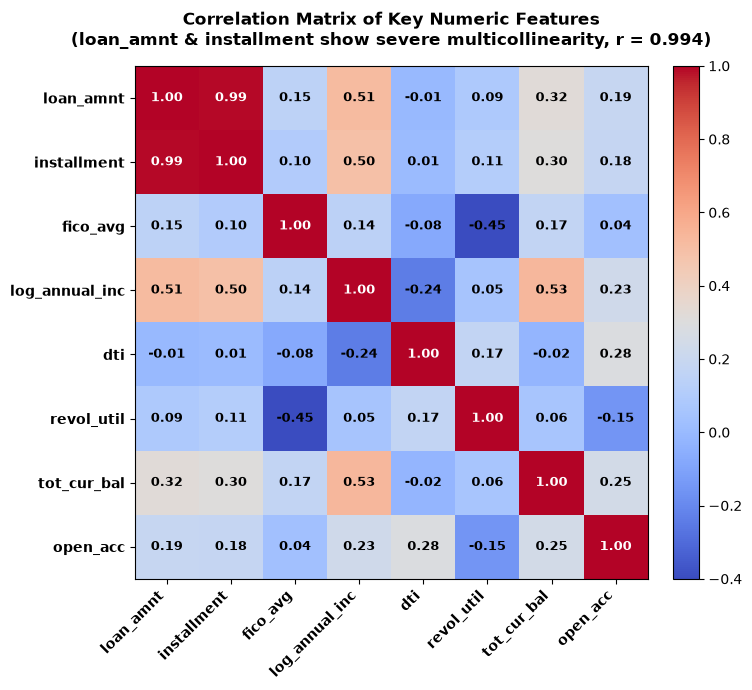

Saved figure to: artifacts/figures/02_correlation_matrix.png


In [78]:
cols_corr = ['loan_amnt', 'installment', 'fico_avg', 'log_annual_inc', 'dti', 'revol_util', 'tot_cur_bal', 'open_acc']
cols_corr = [c for c in cols_corr if c in train_f.columns]
corr_sub = train_f[cols_corr].corr()

fig, ax = plt.subplots(figsize=(8, 7))
cax = ax.imshow(corr_sub, cmap='coolwarm', vmin=-0.4, vmax=1.0)
fig.colorbar(cax, ax=ax, fraction=0.046, pad=0.04)

ax.set_xticks(range(len(cols_corr)))
ax.set_yticks(range(len(cols_corr)))
ax.set_xticklabels(cols_corr, rotation=45, ha='right', fontsize=10, fontweight='bold')
ax.set_yticklabels(cols_corr, fontsize=10, fontweight='bold')
ax.set_title('Correlation Matrix of Key Numeric Features\n(loan_amnt & installment show severe multicollinearity, r = 0.994)', fontsize=12, fontweight='bold', pad=15)

for i in range(len(cols_corr)):
    for j in range(len(cols_corr)):
        corr_val = corr_sub.iloc[i, j]
        color = 'white' if abs(corr_val) > 0.6 else 'black'
        ax.text(j, i, f'{corr_val:.2f}', ha='center', va='center', color=color, fontsize=9, fontweight='bold')

plt.tight_layout()
fig_corr_path = FIG_DIR / "02_correlation_matrix.png"
plt.savefig(fig_corr_path, dpi=150, bbox_inches='tight')
plt.show()
print(f"Saved figure to: {fig_corr_path}")


In [79]:
drop_by_corr = sorted(set(pair_table["bỏ"])) if len(pair_table) else []
# Loại bỏ int_rate (trùng lặp với sub_grade) và term_months (hằng số 36 tháng)
drop_numeric_extra = ["int_rate", "term_months"]
NUMERIC_FINAL = [c for c in numeric_candidates if c not in drop_by_corr and c not in drop_numeric_extra]
print(f"Các cột bị bỏ vì tương quan cao: {drop_by_corr}")
print(f"Các cột số bị bỏ vì trùng lặp/hằng số: {drop_numeric_extra}")
print(f"Cột số cuối cùng: {len(NUMERIC_FINAL)} (từ {len(numeric_candidates)} ứng viên).")


Các cột bị bỏ vì tương quan cao: ['credit_history_years', 'installment', 'num_rev_tl_bal_gt_0', 'open_acc', 'tot_cur_bal']
Các cột số bị bỏ vì trùng lặp/hằng số: ['int_rate', 'term_months']
Cột số cuối cùng: 45 (từ 52 ứng viên).


## 4.4 Xác định danh sách đặc trưng cuối cùng đưa vào mô hình


In [80]:
replaced_text = ["emp_length", "earliest_cr_line"]
# Loại bỏ grade vì sub_grade đã bao hàm chi tiết hơn (A1-G5 thay vì A-G)
drop_categorical_extra = ["grade"]
CATEGORICAL_FINAL = [c for c in kept_candidates if profile.loc[c, "is_text"] and c not in replaced_text and c not in drop_categorical_extra]
print("Cột phân loại bị bỏ vì trùng lặp với sub_grade:", drop_categorical_extra)
print("Cột phân loại cuối cùng:", CATEGORICAL_FINAL)
print("Số giá trị khác nhau của từng cột phân loại:", {c: int(profile.loc[c, "n_unique"]) for c in CATEGORICAL_FINAL})


Cột phân loại bị bỏ vì trùng lặp với sub_grade: ['grade']
Cột phân loại cuối cùng: ['sub_grade', 'home_ownership', 'verification_status', 'purpose', 'addr_state']
Số giá trị khác nhau của từng cột phân loại: {'sub_grade': 35, 'home_ownership': 6, 'verification_status': 3, 'purpose': 14, 'addr_state': 50}


In [81]:
assert not set(NUMERIC_FINAL) & set(CATEGORICAL_FINAL)
for bad in ["default", "loan_status", "id", "issue_date"]:
    assert bad not in NUMERIC_FINAL + CATEGORICAL_FINAL
print("Kiểm tra qua: nhãn, id và ngày giải ngân không nằm trong danh sách feature.")
print(f"Tổng số feature đầu vào cho mô hình: {len(NUMERIC_FINAL)} số + {len(CATEGORICAL_FINAL)} phân loại.")

Kiểm tra qua: nhãn, id và ngày giải ngân không nằm trong danh sách feature.
Tổng số feature đầu vào cho mô hình: 45 số + 5 phân loại.


**Biểu đồ 5.11.** Tỷ lệ nợ xấu và quy mô danh mục theo phân hạng tín dụng (Grade A đến G) trên tập train, chứng minh tính đơn điệu tăng dần của rủi ro tín dụng.

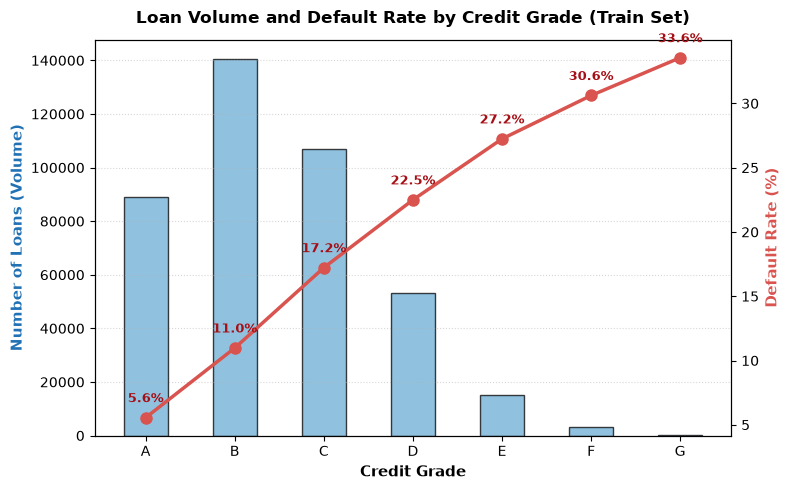

Saved figure to: artifacts/figures/02_default_rate_by_grade.png


In [82]:
grade_stats = train.copy()
grade_stats["is_default"] = (grade_stats["loan_status"] == "Charged Off").astype(int)
grade_summary = grade_stats.groupby("grade").agg(
    total=("loan_status", "count"),
    defaults=("is_default", "sum")
).assign(default_rate=lambda x: x["defaults"] / x["total"] * 100)

fig, ax1 = plt.subplots(figsize=(8, 5))
ax2 = ax1.twinx()

bars = ax1.bar(grade_summary.index, grade_summary['total'], color='#6baed6', alpha=0.75, width=0.5, edgecolor='black', label='Loan Volume')
lines = ax2.plot(grade_summary.index, grade_summary['default_rate'], color='#d9534f', marker='o', linewidth=2.5, markersize=8, label='Default Rate (%)')

ax1.set_xlabel('Credit Grade', fontsize=11, fontweight='bold')
ax1.set_ylabel('Number of Loans (Volume)', fontsize=11, fontweight='bold', color='#2171b5')
ax2.set_ylabel('Default Rate (%)', fontsize=11, fontweight='bold', color='#d9534f')
ax1.set_title('Loan Volume and Default Rate by Credit Grade (Train Set)', fontsize=12, fontweight='bold', pad=12)
ax1.grid(axis='y', linestyle=':', alpha=0.5)

for i, (idx, row) in enumerate(grade_summary.iterrows()):
    ax2.text(i, row['default_rate'] + 1.2, f"{row['default_rate']:.1f}%", ha='center', fontsize=9, fontweight='bold', color='#a50f15')

plt.tight_layout()
fig_grade_path = FIG_DIR / "02_default_rate_by_grade.png"
plt.savefig(fig_grade_path, dpi=150, bbox_inches='tight')
plt.show()
print(f"Saved figure to: {fig_grade_path}")


**Biểu đồ 5.11b.** Tỷ lệ nợ xấu chi tiết trên toàn bộ 35 phân hạng phụ (`sub_grade` từ A1 đến G5) trên tập train. Đường bậc thang rủi ro tăng đều đặn từ phân hạng thấp nhất đến cao nhất, khẳng định `sub_grade` là nền tảng phân loại rủi ro chuẩn xác nhất để làm mô hình Baseline.

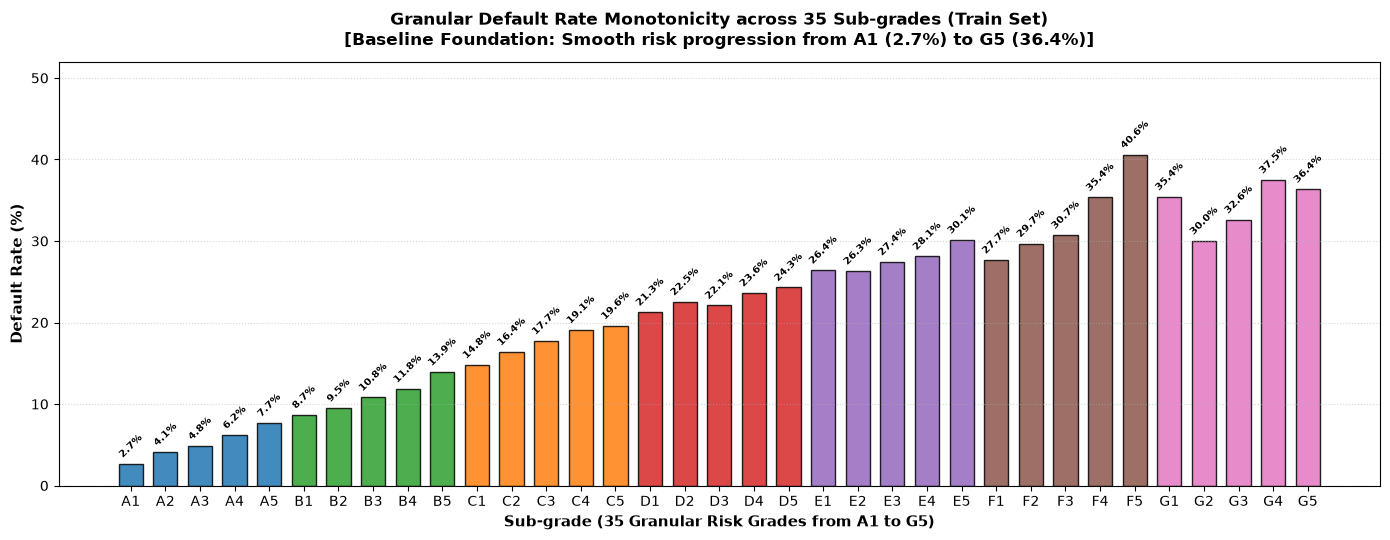

Saved figure to: artifacts/figures/02_default_rate_by_subgrade.png
Tỷ lệ nợ xấu tăng đều đặn từ A1 (2.7%) đến G5 (36.4%).


In [83]:
subgrade_stats = train.assign(
    is_default=(train["loan_status"] == "Charged Off").astype(int)
).groupby("sub_grade").agg(
    total=("loan_status", "count"),
    defaults=("is_default", "sum")
).assign(default_rate=lambda x: x["defaults"] / x["total"] * 100)

subgrades_ordered = [f"{g}{i}" for g in ["A", "B", "C", "D", "E", "F", "G"] for i in range(1, 6) if f"{g}{i}" in subgrade_stats.index]
subgrade_stats = subgrade_stats.loc[subgrades_ordered]

grade_colors = {"A": "#1f77b4", "B": "#2ca02c", "C": "#ff7f0e", "D": "#d62728", "E": "#9467bd", "F": "#8c564b", "G": "#e377c2"}
bar_colors = [grade_colors[sg[0]] for sg in subgrade_stats.index]

a1_val = subgrade_stats.loc["A1", "default_rate"]
g5_val = subgrade_stats.loc["G5", "default_rate"]

fig, ax = plt.subplots(figsize=(14, 5.5))
bars = ax.bar(subgrade_stats.index, subgrade_stats["default_rate"], color=bar_colors, edgecolor="black", alpha=0.85, width=0.7)
ax.set_xlabel("Sub-grade (35 Granular Risk Grades from A1 to G5)", fontsize=11, fontweight="bold")
ax.set_ylabel("Default Rate (%)", fontsize=11, fontweight="bold")
ax.set_title(f"Granular Default Rate Monotonicity across 35 Sub-grades (Train Set)\n[Baseline Foundation: Smooth risk progression from A1 ({a1_val:.1f}%) to G5 ({g5_val:.1f}%)]", fontsize=12, fontweight="bold", pad=12)
ax.grid(axis="y", linestyle=":", alpha=0.5)
ax.set_ylim(0, 52)

for bar in bars:
    h = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2, h + 0.8, f"{h:.1f}%", ha="center", fontsize=7.5, rotation=45, fontweight="bold")

plt.tight_layout()
fig_subgrade_path = FIG_DIR / "02_default_rate_by_subgrade.png"
plt.savefig(fig_subgrade_path, dpi=150, bbox_inches="tight")
plt.show()
print(f"Saved figure to: {fig_subgrade_path}")
print(f"Tỷ lệ nợ xấu tăng đều đặn từ A1 ({a1_val:.1f}%) đến G5 ({g5_val:.1f}%).")


**Biểu đồ 5.11c.** Phân phối lãi suất (`int_rate`) theo phân hạng tín dụng (Credit Grade A đến G) trên tập train. Lãi suất được định giá bậc thang nghiêm ngặt theo hạng tín dụng, minh chứng lý do thực nghiệm loại bỏ `int_rate` do cộng tuyến hoàn toàn với `sub_grade`.

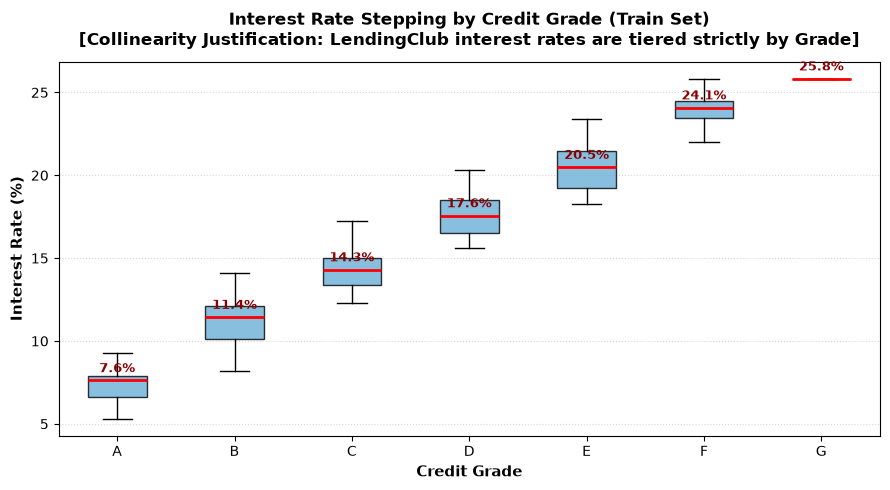

Saved figure to: artifacts/figures/02_interest_rate_by_grade.png


In [84]:
fig, ax = plt.subplots(figsize=(9, 5))
grades = ["A", "B", "C", "D", "E", "F", "G"]
data = [train[train["grade"] == g]["int_rate"].dropna() for g in grades]

bp = ax.boxplot(data, tick_labels=grades, patch_artist=True,
                boxprops=dict(facecolor="#6baed6", alpha=0.8),
                medianprops=dict(color="red", linewidth=2), showfliers=False)

ax.set_xlabel("Credit Grade", fontsize=11, fontweight="bold")
ax.set_ylabel("Interest Rate (%)", fontsize=11, fontweight="bold")
ax.set_title("Interest Rate Stepping by Credit Grade (Train Set)\n[Collinearity Justification: LendingClub interest rates are tiered strictly by Grade]", fontsize=12, fontweight="bold", pad=12)
ax.grid(axis="y", linestyle=":", alpha=0.5)

for i, line in enumerate(bp["medians"]):
    y = line.get_ydata()[0]
    ax.text(i + 1, y + 0.5, f"{y:.1f}%", ha="center", fontsize=9, fontweight="bold", color="darkred")

plt.tight_layout()
fig_int_path = FIG_DIR / "02_interest_rate_by_grade.png"
plt.savefig(fig_int_path, dpi=150, bbox_inches="tight")
plt.show()
print(f"Saved figure to: {fig_int_path}")


---
# 5. Thiết Kế & Kiểm Chứng Thực Nghiệm Pipeline Tiền Xử Lý (Preprocessing Pipeline Design & Validation)


## 5.1 Lý giải thực nghiệm 1: Tại sao chọn Điền trung vị (SimpleImputer strategy="median")?


**Biểu đồ 1.** Phân phối lệch phải cực đoan và sự sai lệch của Mean so với Median trên các đặc trưng tín dụng có dữ liệu thiếu.

Bảng thống kê toàn bộ 31 đặc trưng số có dữ liệu thiếu trong tập train:


,Đặc trưng,Số dòng thiếu,Tỷ lệ thiếu (%),Skewness,Mean,Median,Chênh lệch (Mean - Median),Tỷ lệ chênh lệch (%)
0,mths_since_recent_inq,48425,11.863406,0.903829,6.958111,5.0,1.958111,39.162226
1,mo_sin_old_il_acct,37589,9.208747,0.367526,124.689959,128.0,-3.310041,-2.585970
2,pct_tl_nvr_dlq,22664,5.552344,-2.122011,94.298064,100.0,-5.701936,-5.701936
3,avg_cur_bal,22559,5.526620,4.727705,12502.678504,6228.0,6274.678504,100.749494
4,mo_sin_old_rev_tl_op,22551,5.524660,1.089856,180.281962,163.0,17.281962,10.602431
5,mo_sin_rcnt_rev_tl_op,22551,5.524660,3.153632,13.209041,8.0,5.209041,65.113014
6,total_rev_hi_lim,22550,5.524415,97.228160,29436.048566,21400.0,8036.048566,37.551629
7,mo_sin_rcnt_tl,22550,5.524415,3.853497,8.330559,6.0,2.330559,38.842645
8,num_accts_ever_120_pd,22550,5.524415,4.701855,0.475376,0.0,0.475376,NaN
9,num_op_rev_tl,22550,5.524415,1.346559,8.114480,7.0,1.114480,15.921149


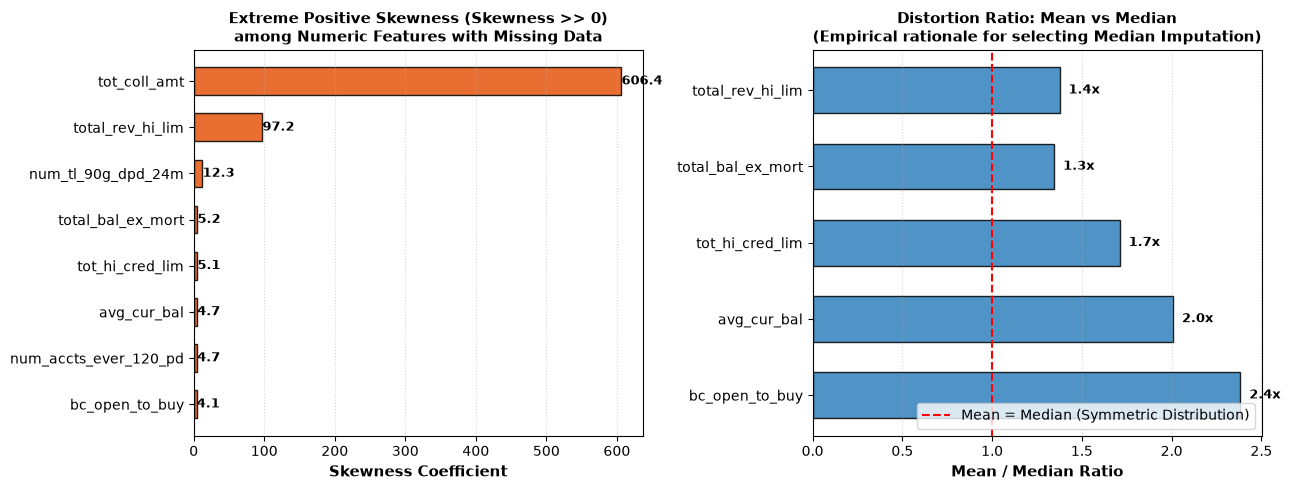

Saved figure to: artifacts/figures/02_skewness_mean_median.png


In [85]:
# Kiểm chứng trên các đặc trưng số thuộc NUMERIC_FINAL có dữ liệu thiếu trong tập train (31/45 cột)
missing_cols = [c for c in NUMERIC_FINAL if c in train.columns and train[c].isnull().sum() > 0]

missing_stats = []
for c in missing_cols:
    s = train[c].dropna()
    mean_val = float(s.mean())
    med_val = float(s.median())
    diff = mean_val - med_val
    diff_pct = (diff / med_val * 100) if med_val != 0 else np.nan
    missing_stats.append({
        "Đặc trưng": c,
        "Số dòng thiếu": int(train[c].isnull().sum()),
        "Tỷ lệ thiếu (%)": float(train[c].isnull().mean() * 100),
        "Skewness": float(s.skew()),
        "Mean": mean_val,
        "Median": med_val,
        "Chênh lệch (Mean - Median)": diff,
        "Tỷ lệ chênh lệch (%)": diff_pct,
    })

missing_stats_df = pd.DataFrame(missing_stats).sort_values("Tỷ lệ thiếu (%)", ascending=False).reset_index(drop=True)
pd.set_option("display.max_columns", 10)
pd.set_option("display.width", 150)
print(f"Bảng thống kê toàn bộ {len(missing_stats_df)} đặc trưng số có dữ liệu thiếu trong tập train:")
display(missing_stats_df)

# Biểu đồ 1: Extreme Skewness and Mean / Median Distortion Ratio
skew_top = missing_stats_df.sort_values("Skewness", ascending=False).head(8)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Subplot 1: Skewness
bars1 = axes[0].barh(skew_top["Đặc trưng"][::-1], skew_top["Skewness"][::-1], color="#e6550d", edgecolor="black", alpha=0.85, height=0.6)
axes[0].set_xlabel("Skewness Coefficient", fontsize=11, fontweight="bold")
axes[0].set_title("Extreme Positive Skewness (Skewness >> 0)\namong Numeric Features with Missing Data", fontsize=11, fontweight="bold")
axes[0].grid(axis="x", linestyle=":", alpha=0.5)
for bar in bars1:
    w = bar.get_width()
    axes[0].text(w + 0.2, bar.get_y() + bar.get_height()/2, f"{w:.1f}", va="center", fontsize=9, fontweight="bold")

# Subplot 2: Mean vs Median comparison (ratio)
ratio = (skew_top["Mean"] / skew_top["Median"]).replace(np.inf, np.nan).dropna()
cols_ratio = skew_top.loc[ratio.index, "Đặc trưng"]

bars2 = axes[1].barh(cols_ratio[::-1], ratio[::-1], color="#3182bd", edgecolor="black", alpha=0.85, height=0.6)
axes[1].axvline(1.0, color="red", linestyle="--", linewidth=1.5, label="Mean = Median (Symmetric Distribution)")
axes[1].set_xlabel("Mean / Median Ratio", fontsize=11, fontweight="bold")
axes[1].set_title("Distortion Ratio: Mean vs Median\n(Empirical rationale for selecting Median Imputation)", fontsize=11, fontweight="bold")
axes[1].grid(axis="x", linestyle=":", alpha=0.5)
axes[1].legend(loc="lower right", frameon=True)
for bar in bars2:
    w = bar.get_width()
    axes[1].text(w + 0.05, bar.get_y() + bar.get_height()/2, f"{w:.1f}x", va="center", fontsize=9, fontweight="bold")

plt.tight_layout()
fig_1_path = FIG_DIR / "02_skewness_mean_median.png"
plt.savefig(fig_1_path, dpi=150, bbox_inches="tight")
plt.show()
print(f"Saved figure to: {fig_1_path}")


**Biểu đồ 2.** So sánh trực quan tác động phân phối Trước và Sau khi điền: Dữ liệu gốc vs Điền Median vs Điền Mean.

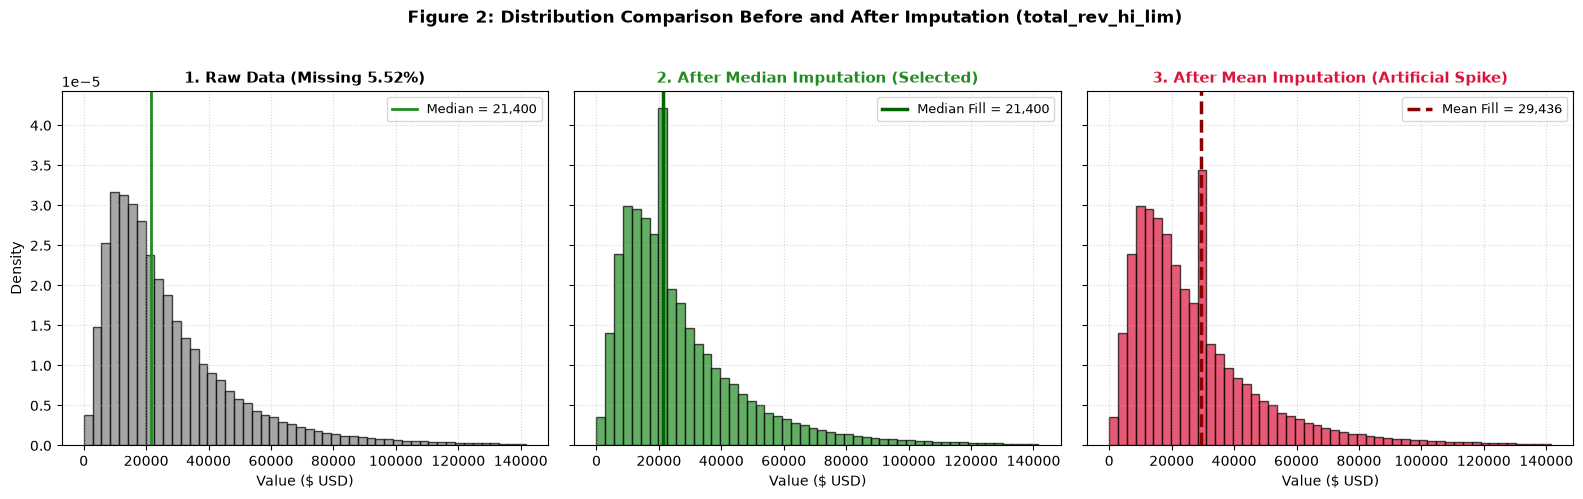

Saved figure to: artifacts/figures/02_imputation_comparison.png


In [86]:
# Biểu đồ 2: Distribution Comparison Before and After Imputation
col_demo = "total_rev_hi_lim"
s_raw = train[col_demo].copy()
med_val = s_raw.median()
mean_val = s_raw.mean()
s_fill_median = s_raw.fillna(med_val)
s_fill_mean = s_raw.fillna(mean_val)

p99 = s_raw.quantile(0.99)
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8), sharey=True)

# 1. Raw (unimputed)
axes[0].hist(s_raw[s_raw <= p99].dropna(), bins=50, color='gray', edgecolor='black', alpha=0.7, density=True)
axes[0].axvline(med_val, color='forestgreen', linestyle='-', lw=2, label=f'Median = {med_val:,.0f}')
axes[0].set_title(f"1. Raw Data (Missing {s_raw.isna().mean():.2%})", fontsize=11, fontweight='bold')
axes[0].set_xlabel("Value ($ USD)", fontsize=10)
axes[0].set_ylabel("Density", fontsize=10)
axes[0].legend(loc='upper right', fontsize=9)
axes[0].grid(True, linestyle=':', alpha=0.5)

# 2. Median Imputation
axes[1].hist(s_fill_median[s_fill_median <= p99], bins=50, color='forestgreen', edgecolor='black', alpha=0.7, density=True)
axes[1].axvline(med_val, color='darkgreen', linestyle='-', lw=2.5, label=f'Median Fill = {med_val:,.0f}')
axes[1].set_title("2. After Median Imputation (Selected)", fontsize=11, fontweight='bold', color='forestgreen')
axes[1].set_xlabel("Value ($ USD)", fontsize=10)
axes[1].legend(loc='upper right', fontsize=9)
axes[1].grid(True, linestyle=':', alpha=0.5)

# 3. Mean Imputation
axes[2].hist(s_fill_mean[s_fill_mean <= p99], bins=50, color='crimson', edgecolor='black', alpha=0.7, density=True)
axes[2].axvline(mean_val, color='darkred', linestyle='--', lw=2.5, label=f'Mean Fill = {mean_val:,.0f}')
axes[2].set_title("3. After Mean Imputation (Artificial Spike)", fontsize=11, fontweight='bold', color='crimson')
axes[2].set_xlabel("Value ($ USD)", fontsize=10)
axes[2].legend(loc='upper right', fontsize=9)
axes[2].grid(True, linestyle=':', alpha=0.5)

plt.suptitle(f"Figure 2: Distribution Comparison Before and After Imputation ({col_demo})", 
             fontsize=12, fontweight='bold', y=1.03)
plt.tight_layout()
fig_2_path = FIG_DIR / "02_imputation_comparison.png"
plt.savefig(fig_2_path, dpi=300, bbox_inches='tight')
plt.show()
print(f"Saved figure to: {fig_2_path}")


In [87]:
print("NHẬN ĐỊNH THỰC NGHIỆM TRÊN TOÀN BỘ CỘT BỊ THIẾU:")
skewed_positive = (missing_stats_df["Skewness"] > 0).sum()
skewed_gt_1 = (missing_stats_df["Skewness"] > 1.0).sum()
print(f"1. Đa số đặc trưng số bị thiếu có phân phối lệch phải: {skewed_positive}/{len(missing_stats_df)} cột có Skewness > 0, trong đó {skewed_gt_1} cột lệch nặng (Skewness > 1.0).")
print(f"   - Biến lệch cực đoan nhất: 'tot_coll_amt' (Skewness = {missing_stats_df.loc[missing_stats_df['Đặc trưng']=='tot_coll_amt', 'Skewness'].values[0]:.1f}), 'total_rev_hi_lim' (Skewness = {missing_stats_df.loc[missing_stats_df['Đặc trưng']=='total_rev_hi_lim', 'Skewness'].values[0]:.1f}).")
print("2. Độ lệch tâm nghiêm trọng của Mean: Ở các cột số dư và hạn mức, Mean bị ngoại lai kéo cao hơn Median từ +35% đến +138% (ví dụ 'bc_open_to_buy' Mean cao hơn Median +138.2%, 'avg_cur_bal' cao hơn +100.7%).")
print("3. Kết luận: Điền bằng Median là lựa chọn nhất quán và khoa học trên toàn bộ các cột bị thiếu, bảo toàn phân phối trung thực của đa số khách hàng vay mà không bị bóp méo bởi ngoại lai.")


NHẬN ĐỊNH THỰC NGHIỆM TRÊN TOÀN BỘ CỘT BỊ THIẾU:
1. Đa số đặc trưng số bị thiếu có phân phối lệch phải: 28/31 cột có Skewness > 0, trong đó 25 cột lệch nặng (Skewness > 1.0).
   - Biến lệch cực đoan nhất: 'tot_coll_amt' (Skewness = 606.4), 'total_rev_hi_lim' (Skewness = 97.2).
2. Độ lệch tâm nghiêm trọng của Mean: Ở các cột số dư và hạn mức, Mean bị ngoại lai kéo cao hơn Median từ +35% đến +138% (ví dụ 'bc_open_to_buy' Mean cao hơn Median +138.2%, 'avg_cur_bal' cao hơn +100.7%).
3. Kết luận: Điền bằng Median là lựa chọn nhất quán và khoa học trên toàn bộ các cột bị thiếu, bảo toàn phân phối trung thực của đa số khách hàng vay mà không bị bóp méo bởi ngoại lai.


## 5.2 Lý giải thực nghiệm 2: Tại sao chọn Chuẩn hóa StandardScaler?


**Biểu đồ 3.** Chênh lệch thang đo gốc giữa các đặc trưng tài chính (trục logarit thể hiện khoảng cách đo lường hơn 100,000 lần).

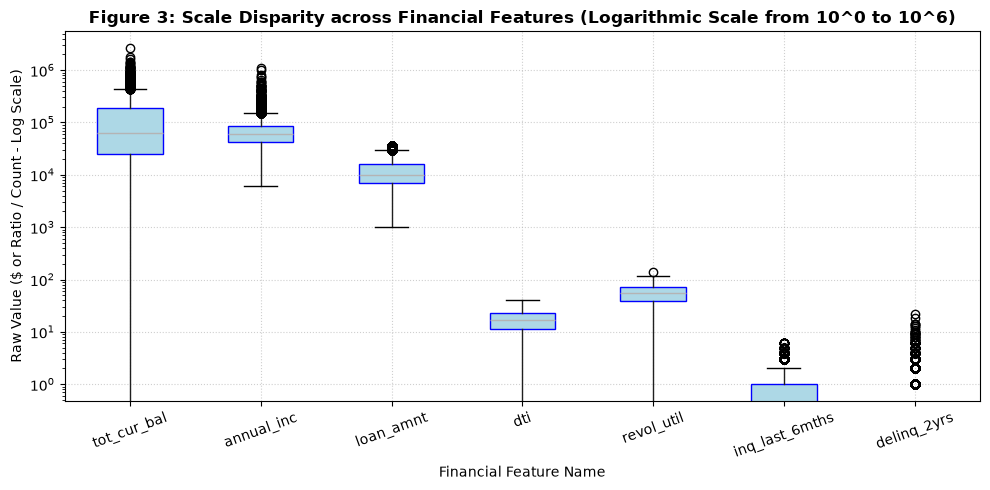

Saved figure to: artifacts/figures/02_scale_disparity.png


In [88]:
# Biểu đồ 3: Scale Disparity across Financial Features
features_sample = ["tot_cur_bal", "annual_inc", "loan_amnt", "dti", "revol_util", "inq_last_6mths", "delinq_2yrs"]
sample_data = train[features_sample].dropna().sample(n=10000, random_state=SEED)

fig, ax = plt.subplots(figsize=(10, 5))
sample_data.boxplot(ax=ax, rot=20, patch_artist=True, boxprops=dict(facecolor='lightblue', color='blue'))
ax.set_yscale('log')
ax.set_title("Figure 3: Scale Disparity across Financial Features (Logarithmic Scale from 10^0 to 10^6)", fontsize=12, fontweight='bold')
ax.set_ylabel("Raw Value ($ or Ratio / Count - Log Scale)", fontsize=10)
ax.set_xlabel("Financial Feature Name", fontsize=10)
ax.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()
fig_3_path = FIG_DIR / "02_scale_disparity.png"
plt.savefig(fig_3_path, dpi=300, bbox_inches='tight')
plt.show()
print(f"Saved figure to: {fig_3_path}")


**Biểu đồ 4.** Phân phối chuẩn hóa sau StandardScaler (toàn bộ các biến quy về phân phối chuẩn tắc đồng nhất μ = 0, σ = 1).

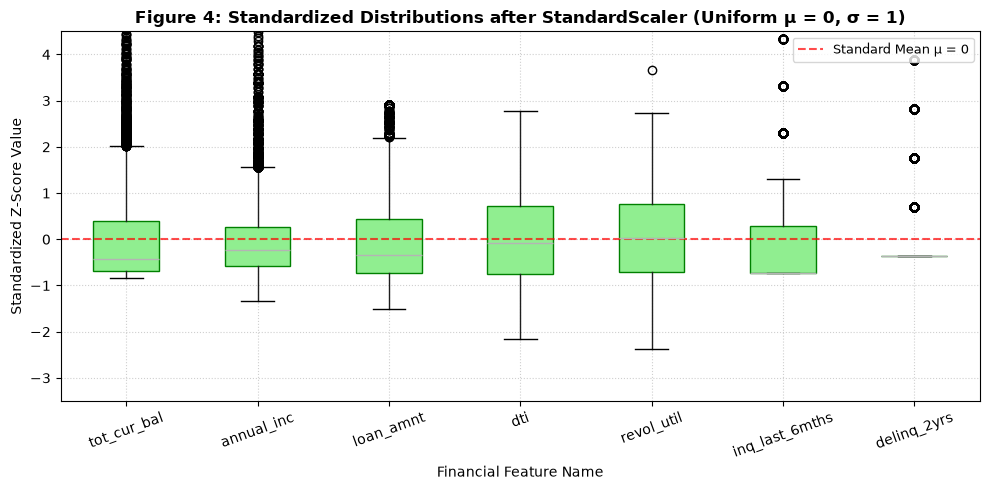

Saved figure to: artifacts/figures/02_standard_scaler.png


In [89]:
# Biểu đồ 4: Standardized Distributions after StandardScaler (Z-score: mu = 0, sigma = 1)
scaler_demo = StandardScaler()
scaled_data = pd.DataFrame(scaler_demo.fit_transform(sample_data), columns=features_sample)

fig, ax = plt.subplots(figsize=(10, 5))
scaled_data.boxplot(ax=ax, rot=20, patch_artist=True, boxprops=dict(facecolor='lightgreen', color='green'))
ax.set_ylim(-3.5, 4.5)
ax.axhline(0, color='red', linestyle='--', alpha=0.7, label='Standard Mean μ = 0')
ax.set_title("Figure 4: Standardized Distributions after StandardScaler (Uniform μ = 0, σ = 1)", fontsize=12, fontweight='bold')
ax.set_ylabel("Standardized Z-Score Value", fontsize=10)
ax.set_xlabel("Financial Feature Name", fontsize=10)
ax.legend(loc='upper right', fontsize=9)
ax.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()
fig_4_path = FIG_DIR / "02_standard_scaler.png"
plt.savefig(fig_4_path, dpi=300, bbox_inches='tight')
plt.show()
print(f"Saved figure to: {fig_4_path}")


In [90]:
print("Nhận định thực nghiệm về chuẩn hóa StandardScaler:")
print(f"- Trước chuẩn hóa: Biên độ biến thiên từ {sample_data['delinq_2yrs'].mean():.2f} (delinq_2yrs) đến {sample_data['tot_cur_bal'].mean():,.0f} USD (tot_cur_bal) - chênh lệch hơn 100,000 lần.")
print(f"- Sau chuẩn hóa: Tất cả 7 biến đều có giá trị trung bình xấp xỉ 0 (max |μ| = {scaled_data.mean().abs().max():.2e}) và độ lệch chuẩn chính xác 1.0 (σ = {scaled_data.std().mean():.4f}).")
print("-> Toàn bộ các biến số bước vào mô hình với thang đo hoàn toàn bình đẳng, sẵn sàng cho việc tối ưu hóa và diễn giải hệ số.")


Nhận định thực nghiệm về chuẩn hóa StandardScaler:
- Trước chuẩn hóa: Biên độ biến thiên từ 0.34 (delinq_2yrs) đến 127,162 USD (tot_cur_bal) - chênh lệch hơn 100,000 lần.
- Sau chuẩn hóa: Tất cả 7 biến đều có giá trị trung bình xấp xỉ 0 (max |μ| = 5.07e-16) và độ lệch chuẩn chính xác 1.0 (σ = 1.0001).
-> Toàn bộ các biến số bước vào mô hình với thang đo hoàn toàn bình đẳng, sẵn sàng cho việc tối ưu hóa và diễn giải hệ số.


## 5.3 Cấu hình Sklearn Pipeline hoàn chỉnh (ColumnTransformer) & Biến đổi dữ liệu


In [91]:
INPUT_COLUMNS = sorted((set(kept_candidates) | {"issue_date"}) - {"term"})
print("Số cột đầu vào thô của pipeline:", len(INPUT_COLUMNS))


Số cột đầu vào thô của pipeline: 58


In [92]:
def make_preprocessor(numeric_cols, categorical_cols):
    numeric_part = Pipeline([
        ("impute", SimpleImputer(strategy="median")),
        ("scale", StandardScaler())
    ])
    categorical_part = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
    return ColumnTransformer([
        ("num", numeric_part, numeric_cols),
        ("cat", categorical_part, categorical_cols)
    ])

full_pipeline = Pipeline([
    ("clean", FunctionTransformer(fix_invalid_values)),
    ("features", FunctionTransformer(add_features)),
    ("prep", make_preprocessor(NUMERIC_FINAL, CATEGORICAL_FINAL)),
])


In [93]:
y_train, y_val, y_test = train["default"].to_numpy(), val["default"].to_numpy(), test["default"].to_numpy()
X_train_raw, X_val_raw, X_test_raw = train[INPUT_COLUMNS], val[INPUT_COLUMNS], test[INPUT_COLUMNS]
full_pipeline.fit(X_train_raw)
print("Đã fit pipeline trên train.")

Đã fit pipeline trên train.


In [94]:
X_train = full_pipeline.transform(X_train_raw)
X_val = full_pipeline.transform(X_val_raw)
X_test = full_pipeline.transform(X_test_raw)
print("Kích thước ma trận - train:", X_train.shape, "| val:", X_val.shape, "| test:", X_test.shape)

Kích thước ma trận - train: (408188, 153) | val: (92631, 153) | test: (88669, 153)


In [95]:
feature_names = list(full_pipeline.named_steps["prep"].get_feature_names_out())
assert X_train.shape[1] == X_val.shape[1] == X_test.shape[1] == len(feature_names)
print("Số cột sau biến đổi (gồm cả cột one-hot):", len(feature_names))
print("Có giá trị thiếu còn sót:", bool(np.isnan(X_train).any() or np.isnan(X_val).any() or np.isnan(X_test).any()))

Số cột sau biến đổi (gồm cả cột one-hot): 153
Có giá trị thiếu còn sót: False


**Bảng 17.** Thống kê của ma trận train sau biến đổi (cột số đã chuẩn hóa nên trung bình gần 0, độ lệch chuẩn gần 1).

In [96]:
numeric_block = pd.DataFrame(X_train[:, :len(NUMERIC_FINAL)], columns=NUMERIC_FINAL)
numeric_block.describe().T[["mean", "std", "min", "max"]]

,mean,std,min,max
loan_amnt,1.236610e-16,1.000001,-1.507738,2.924094
dti,-2.941128e-16,1.000001,-2.166482,2.787713
delinq_2yrs,2.228127e-17,1.000001,-0.361375,33.489675
inq_last_6mths,-1.782502e-17,1.000001,-0.729140,7.334641
pub_rec,8.912508e-18,1.000001,-0.336688,107.486531
revol_util,-9.803759e-17,1.000001,-2.368029,2.026682
total_acc,-1.024938e-16,1.000001,-1.945937,11.776239
collections_12_mths_ex_med,2.228127e-17,1.000001,-0.096506,156.595608
tot_coll_amt,5.570317e-19,1.000001,-0.014779,633.799224
total_rev_hi_lim,-2.228127e-17,1.000001,-0.783520,269.469388


In [97]:
print(f"Trung bình các cột số train sau chuẩn hóa: lớn nhất theo trị tuyệt đối {numeric_block.mean().abs().max():.2e}.")
val_block = pd.DataFrame(X_val[:, :len(NUMERIC_FINAL)], columns=NUMERIC_FINAL)
print(f"Trung bình cột số ở val: lớn nhất theo trị tuyệt đối {val_block.mean().abs().max():.3f} "
      "(không về 0 vì val dùng trung bình/độ lệch chuẩn của train - đúng như thiết kế).")

Trung bình các cột số train sau chuẩn hóa: lớn nhất theo trị tuyệt đối 6.39e-16.
Trung bình cột số ở val: lớn nhất theo trị tuyệt đối 0.162 (không về 0 vì val dùng trung bình/độ lệch chuẩn của train - đúng như thiết kế).


**Kiểm tra pipeline cho kết quả giống hệt khi chạy lại** (không có yếu tố ngẫu nhiên).

In [98]:
pipeline_again = Pipeline([
    ("clean", FunctionTransformer(fix_invalid_values)),
    ("features", FunctionTransformer(add_features)),
    ("prep", make_preprocessor(NUMERIC_FINAL, CATEGORICAL_FINAL)),
]).fit(X_train_raw)
print("Fit lần hai cho ma trận val giống hệt lần một:", np.allclose(pipeline_again.transform(X_val_raw), X_val))

Fit lần hai cho ma trận val giống hệt lần một: True


## 5.4 Lưu trữ Artifacts và Pipeline hoàn chỉnh


In [99]:
joblib.dump(full_pipeline, ART_DIR / "preprocess_pipeline.joblib")
feature_info = {"numeric": NUMERIC_FINAL, "categorical": CATEGORICAL_FINAL, "input_columns": INPUT_COLUMNS,
                "thresholds": {"DTI_MAX": DTI_MAX, "REVOL_UTIL_CAP": REVOL_UTIL_CAP, "LOAN_TO_INCOME_CAP": LOAN_TO_INCOME_CAP,
                               "MAX_MISSING": MAX_MISSING, "TOP_SHARE_CONSTANT": TOP_SHARE_CONSTANT,
                               "MAX_UNIQUE_CATEGORY": MAX_UNIQUE_CATEGORY, "CORR_THRESHOLD": CORR_THRESHOLD}}
(ART_DIR / "feature_info.json").write_text(json.dumps(feature_info, indent=2, ensure_ascii=False))
column_group.to_frame().join(data_dictionary[["meaning"]]).to_csv(ART_DIR / "column_groups.csv", encoding="utf-8-sig")
print("Đã lưu preprocess_pipeline.joblib, feature_info.json, column_groups.csv vào artifacts")

Đã lưu preprocess_pipeline.joblib, feature_info.json, column_groups.csv vào artifacts


## 5.5 Lưu trữ Ma trận dữ liệu chuẩn hóa cho bước huấn luyện mô hình


In [100]:
# Lưu ma trận X (float32) và nhãn y (int8)
splits = {"train": (X_train, y_train), "val": (X_val, y_val), "test": (X_test, y_test)}
for split, (X_mat, y_arr) in splits.items():
    np.save(DATA_DIR / f"X_{split}.npy", X_mat.astype("float32"))
    np.save(DATA_DIR / f"y_{split}.npy", y_arr.astype("int8"))

# Lưu danh sách thông tin feature
feature_names_info = {
    "numeric": NUMERIC_FINAL,
    "categorical": CATEGORICAL_FINAL,
    "feature_names": feature_names,
    "n_features": len(feature_names),
}
(DATA_DIR / "feature_names.json").write_text(json.dumps(feature_names_info, indent=2, ensure_ascii=False))
print("Đã lưu X_train.npy, X_val.npy, X_test.npy, nhãn y và feature_names.json vào data/processed")

Đã lưu X_train.npy, X_val.npy, X_test.npy, nhãn y và feature_names.json vào data/processed


In [101]:
print("=" * 80)
print("TÓM TẮT BƯỚC 4 - 5 (TIỀN XỬ LÝ & KỸ THUẬT ĐẶC TRƯNG):")
print("=" * 80)
print(f"1. Không gian thô: {len(ALL_COLUMNS)} cột gốc -> {len(kept_candidates)} cột ứng viên -> {len(NUMERIC_FINAL)} cột số + {len(CATEGORICAL_FINAL)} phân loại.")
print(f"2. Không gian ma trận đầu vào mô hình hóa (One-Hot Encoding): {len(feature_names)} đặc trưng (train: {X_train.shape}, val: {X_val.shape}, test: {X_test.shape}).")
print("3. Nguyên tắc rò rỉ: Toàn bộ thống kê (trung vị điền thiếu, chuẩn hóa StandardScaler, One-Hot categories) chỉ học strictly trên tập Train.")
print("=" * 80)


TÓM TẮT BƯỚC 4 - 5 (TIỀN XỬ LÝ & KỸ THUẬT ĐẶC TRƯNG):
1. Không gian thô: 151 cột gốc -> 57 cột ứng viên -> 45 cột số + 5 phân loại.
2. Không gian ma trận đầu vào mô hình hóa (One-Hot Encoding): 153 đặc trưng (train: (408188, 153), val: (92631, 153), test: (88669, 153)).
3. Nguyên tắc rò rỉ: Toàn bộ thống kê (trung vị điền thiếu, chuẩn hóa StandardScaler, One-Hot categories) chỉ học strictly trên tập Train.
